# Fase 4 — Modelagem

## Consumer Credit Risk

Nesta etapa serão desenvolvidos e avaliados modelos de classificação para previsão de inadimplência.

### Modelos previstos

- Dummy Classifier (`strategy="prior"`)
- Decision Tree
- Random Forest
- XGBoost
- LightGBM

### Métricas de avaliação

- ROC AUC
- PR AUC
- Acurácia

### Validação cruzada

Será utilizada validação cruzada com `StratifiedKFold`, com 5 splits, aplicada somente aos dados de treino.

As métricas utilizadas na validação cruzada serão:

- ROC AUC
- Acurácia



#### A diferença entre validação cruzada e teste

Funciona da seguinte forma:

```text

                 BASE COMPLETA
                       │
             ┌─────────┴─────────┐
             ↓                   ↓
          TREINO                TESTE
           75%                   25%
             │                    │
             ↓                    │
     VALIDAÇÃO CRUZADA            │
             │                    │
       ┌─────┼─────┐              │
       ↓     ↓     ↓              │
     Fold1 Fold2 ... Fold5        │
             │                    │
             ↓                    │
     avaliar/comparar             │
        o modelo                  │
             │                    │
             └──────────┐         │
                        ↓         │
                 treinar em todo  │
                    o treino      │
                        │         │
                        └────────→│
                                  ↓
                           AVALIAÇÃO NO
                               TESTE
```
A **validação cruzada** ajuda a entender como o modelo se comporta durante o desenvolvimento usando somente o conjunto de treino.

O **teste** é uma avaliação separada em dados que ficaram fora desse processo.


## 1. Carregamento dos dados

Nesta etapa, carregamos a base de dados utilizada no projeto por meio da função definida no módulo `data.py`.

In [1]:
import pandas as pd

In [2]:
from consumer_credit_risk.data import carregar_dados_credito

df = carregar_dados_credito()

df.head()

,inadimplente_2anos,idade,renda_mensal,dependentes,uso_limite_rotativo,razao_divida,linhas_credito_abertas,financiamentos_imobiliarios,atrasos_30_59_dias,atrasos_60_89_dias,atrasos_90_mais_dias
0,1,45,9120.0,2.0,0.766127,0.802982,13,6,2,0,0
1,0,40,2600.0,1.0,0.957151,0.121876,4,0,0,0,0
2,0,38,3042.0,0.0,0.658180,0.085113,2,0,1,0,1
3,0,30,3300.0,0.0,0.233810,0.036050,5,0,0,0,0
4,0,49,63588.0,0.0,0.907239,0.024926,7,1,1,0,0


## 2. Separação das variáveis explicativas e da variável-alvo

A variável `inadimplente_2anos` será utilizada como variável-alvo (`y`).

As demais variáveis serão utilizadas como variáveis explicativas (`X`).

In [3]:
X = df.drop(columns="inadimplente_2anos")
y = df["inadimplente_2anos"]

print("Dimensão de X:", X.shape)
print("Dimensão de y:", y.shape)

y.value_counts(normalize=True)

Dimensão de X: (150000, 10)
Dimensão de y: (150000,)


inadimplente_2anos
0    0.93316
1    0.06684
Name: proportion, dtype: float64

## 3. Separação entre treino e teste

Os dados serão divididos em:

- 75% para treino
- 25% para teste

Será utilizado `stratify=y` para preservar a proporção de inadimplentes nas duas bases.

In [4]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [5]:
print("Tamanho do treino:", X_treino.shape)
print("Tamanho do teste:", X_teste.shape)

print("\nProporção de inadimplentes:")
print(f"Base completa: {y.mean():.4f}")
print(f"Treino:        {y_treino.mean():.4f}")
print(f"Teste:         {y_teste.mean():.4f}")

Tamanho do treino: (112500, 10)
Tamanho do teste: (37500, 10)

Proporção de inadimplentes:
Base completa: 0.0668
Treino:        0.0668
Teste:         0.0668


O ponto mais importante aqui é:
```python
stratify=y
```
Como `y` é bastante desbalanceado, queremos que a proporção de `0` e `1` da base original seja aproximadamente preservada tanto no treino quanto no teste.

E o:
```python
random_state=42
```
é particularmente importante para nosso projeto: usando o **mesmo** `random_state` **da Fase 3**, reproduzimos exatamente a mesma divisão dos dados, em vez de criar outro conjunto de treino e teste.

As três proporções devem ficar praticamente iguais.

## 4. Pipeline de pré-processamento

O pré-processamento será incorporado ao pipeline de modelagem para garantir que os parâmetros aprendidos durante a preparação, como as medianas utilizadas na imputação, sejam calculados somente a partir dos dados de treino de cada etapa.

Isso é especialmente importante durante a validação cruzada, evitando vazamento de dados.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from consumer_credit_risk.preprocessing import preparar_dados_credito

In [7]:
colunas_imputacao = [
    "renda_mensal",
    "dependentes",
    "renda_por_dependente",
    "sobra_caixa",
]

preparo = FunctionTransformer(
    preparar_dados_credito,
    validate=False
)

imputacao = ColumnTransformer(
    transformers=[
        (
            "imputer_mediana",
            SimpleImputer(strategy="median"),
            colunas_imputacao,
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

## 5. Dummy Classifier

O `DummyClassifier` será utilizado como modelo de referência (baseline).

Será utilizada a estratégia `prior`, que considera apenas a distribuição das classes observada nos dados de treino, sem aprender relações entre as variáveis explicativas e a inadimplência.

In [8]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(
    strategy="prior"
)

In [9]:
pipeline_dummy = Pipeline(
    steps=[
        ("preparo", preparo),
        ("imputacao", imputacao),
        ("modelo", dummy),
    ]
)

pipeline_dummy

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparo', ...), ('imputacao', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...x783d12b0be20>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDiction

## 6. Validação cruzada

Será utilizada validação cruzada com `StratifiedKFold`, utilizando 5 splits.

A estratificação preserva aproximadamente a proporção das classes em cada fold, o que é especialmente importante neste problema devido ao desbalanceamento da variável-alvo.

A validação cruzada será realizada exclusivamente sobre os dados de treino.

In [10]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

### Verificação da estratificação

Antes da validação dos modelos, será verificada a proporção da classe positiva em cada um dos 5 folds.

In [11]:
for fold, (indice_treino, indice_validacao) in enumerate(
    cv.split(X_treino, y_treino),
    start=1
):
    y_fold_treino = y_treino.iloc[indice_treino]
    y_fold_validacao = y_treino.iloc[indice_validacao]

    print(
        f"Fold {fold} | "
        f"Treino: {y_fold_treino.mean():.4f} | "
        f"Validação: {y_fold_validacao.mean():.4f}"
    )

Fold 1 | Treino: 0.0668 | Validação: 0.0668
Fold 2 | Treino: 0.0668 | Validação: 0.0668
Fold 3 | Treino: 0.0668 | Validação: 0.0668
Fold 4 | Treino: 0.0668 | Validação: 0.0668
Fold 5 | Treino: 0.0668 | Validação: 0.0668


### Cross-validation — Dummy Classifier

O Dummy Classifier será avaliado nos dados de treino utilizando validação cruzada estratificada com 5 folds.

As métricas utilizadas serão ROC AUC e Acurácia.

In [12]:
from sklearn.model_selection import cross_validate

resultado_cv_dummy = cross_validate(
    pipeline_dummy,
    X_treino,
    y_treino,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "acuracia": "accuracy",
    }
)

In [13]:
for fold in range(5):
    print(
        f"Fold {fold + 1} | "
        f"ROC AUC: {resultado_cv_dummy['test_roc_auc'][fold]:.4f} | "
        f"Acurácia: {resultado_cv_dummy['test_acuracia'][fold]:.4f}"
    )

Fold 1 | ROC AUC: 0.5000 | Acurácia: 0.9332
Fold 2 | ROC AUC: 0.5000 | Acurácia: 0.9332
Fold 3 | ROC AUC: 0.5000 | Acurácia: 0.9332
Fold 4 | ROC AUC: 0.5000 | Acurácia: 0.9332
Fold 5 | ROC AUC: 0.5000 | Acurácia: 0.9332


**Uma previsão antes de executar**

Este é um ótimo momento para testar se entendemos as métricas.

Como o Dummy com `strategy="prior"` dá essencialmente a **mesma probabilidade de inadimplência para todos os clientes**, esperamos que seu:

**ROC AUC fique em torno de** `0.50`.

Isso representa ausência de capacidade de **discriminar/rankear** quem é mais ou menos propenso à inadimplência.

Já a **acurácia provavelmente ficará perto de** `0.9332`, ou `93,32%`.

Parece excelente à primeira vista, mas sabemos que aproximadamente 93,32% da base pertence à classe `0`. Então essa acurácia alta pode ser bastante enganosa.

In [14]:
import numpy as np

roc_auc_dummy_media = resultado_cv_dummy["test_roc_auc"].mean()
roc_auc_dummy_std = resultado_cv_dummy["test_roc_auc"].std()

acuracia_dummy_media = resultado_cv_dummy["test_acuracia"].mean()
acuracia_dummy_std = resultado_cv_dummy["test_acuracia"].std()

print(
    f"ROC AUC:  {roc_auc_dummy_media:.4f} "
    f"(± {roc_auc_dummy_std:.4f})"
)

print(
    f"Acurácia: {acuracia_dummy_media:.4f} "
    f"(± {acuracia_dummy_std:.4f})"
)

ROC AUC:  0.5000 (± 0.0000)
Acurácia: 0.9332 (± 0.0000)


## 7. Avaliação dos modelos na base de teste

Após a validação cruzada realizada exclusivamente nos dados de treino, os modelos serão ajustados utilizando toda a base de treino e avaliados na base de teste.

As métricas utilizadas na avaliação serão:

- ROC AUC
- PR AUC
- Acurácia

A base de teste não foi utilizada durante o ajuste do pré-processamento, treinamento ou validação cruzada dos modelos.

Essa última frase é importante metodologicamente. Até agora nosso fluxo foi:
```text
    BASE COMPLETA
        │
        ├──────── 75% → TREINO
        │                 │
        │                 └── StratifiedKFold
        │                       ├── Fold 1
        │                       ├── Fold 2
        │                       ├── Fold 3
        │                       ├── Fold 4
        │                       └── Fold 5
        │
        └──────── 25% → TESTE
                            ↑
                    ainda preservado
```
Agora, pela primeira vez, vamos utilizar esse teste para avaliar o modelo.

### 7.1 Dummy Classifier

O pipeline do Dummy Classifier será ajustado utilizando toda a base de treino.

Em seguida, serão realizadas previsões sobre a base de teste para calcular ROC AUC, PR AUC e Acurácia.

In [15]:
pipeline_dummy.fit(X_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparo', ...), ('imputacao', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['idade','renda_mensal','dependentes',...,'atrasos_30_59_dias', 'atrasos_60_89_dias','atrasos_90_mais_dias']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...x783d12b0be20>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


Aqui existe um detalhe muito importante.

Quando executamos:
```python
pipeline_dummy.fit(X_treino, y_treino)
```
não estamos treinando somente o Dummy. O `Pipeline` executa sequencialmente:
```text
    X_treino
        │
        ▼
    preparo
    FunctionTransformer
        │
        ▼
    imputacao
    SimpleImputer
        │
        ▼
    modelo
    DummyClassifier
```
Portanto, agora a mediana utilizada pelo `SimpleImputer` é aprendida utilizando **todo o conjunto de treino**.

Isso está correto porque terminamos a validação cruzada e estamos preparando o modelo para avaliar o conjunto de teste.

#### Previsões na base de teste

Serão geradas:

- as classes previstas, utilizadas para calcular a Acurácia;
- as probabilidades da classe positiva (inadimplente), utilizadas para calcular ROC AUC e PR AUC.

In [16]:
y_pred_dummy = pipeline_dummy.predict(X_teste)

y_proba_dummy = pipeline_dummy.predict_proba(X_teste)[:, 1]

O que cada variável contém:

- `y_pred_dummy` → classe prevista (`0` ou `1`)
- `y_proba_dummy` → probabilidade prevista de ser inadimplente (`classe 1`)

O `[:, 1]` seleciona a probabilidade da classe 1, que é a nossa classe positiva: **inadimplente**.

#### Métricas do Dummy Classifier

O modelo será avaliado na base de teste utilizando:

- ROC AUC
- PR AUC
- Acurácia

In [17]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
)

In [18]:
roc_auc_dummy_teste = roc_auc_score(
    y_teste,
    y_proba_dummy
)

pr_auc_dummy_teste = average_precision_score(
    y_teste,
    y_proba_dummy
)

acuracia_dummy_teste = accuracy_score(
    y_teste,
    y_pred_dummy
)

In [19]:
print(f"ROC AUC:  {roc_auc_dummy_teste:.4f}")
print(f"PR AUC:   {pr_auc_dummy_teste:.4f}")
print(f"Acurácia: {acuracia_dummy_teste:.4f}")

ROC AUC:  0.5000
PR AUC:   0.0668
Acurácia: 0.9332


#### Interpretação do baseline

O Dummy Classifier apresentou:

- ROC AUC de 0,5000;
- PR AUC de 0,0668;
- Acurácia de 0,9332.

Apesar da elevada acurácia, o modelo não possui capacidade discriminatória, pois utiliza apenas a distribuição das classes.

Os resultados do Dummy serão utilizados como baseline para comparação com os demais modelos.

## 8. Decision Tree

O segundo modelo avaliado será uma Árvore de Decisão (`DecisionTreeClassifier`).

O modelo será incorporado ao mesmo pipeline de pré-processamento utilizado no Dummy Classifier, garantindo que os dois modelos sejam avaliados sob as mesmas condições.

In [20]:
from sklearn.tree import DecisionTreeClassifier

arvore = DecisionTreeClassifier(
    random_state=42
)

In [21]:
pipeline_arvore = Pipeline(
    steps=[
        ("preparo", preparo),
        ("imputacao", imputacao),
        ("modelo", arvore),
    ]
)

pipeline_arvore

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparo', ...), ('imputacao', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...x783d12b0be20>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDiction

**O que estamos fazendo**

A estrutura agora é:
```text
    X
    │
    ├── preparo
    │
    ├── imputacao
    │
    └── DecisionTreeClassifier
```
Observe que usamos:
```python
DecisionTreeClassifier(
    random_state=42
)
```
e **não definimos ainda** coisas como:
```python
max_depth=
min_samples_split=
min_samples_leaf=
```
Portanto, estamos começando com a **Decision Tree padrão do scikit-learn**, apenas fixando `random_state=42` para reprodutibilidade.

Isso é importante: não vamos ajustar hiperparâmetros por conta própria antes de observar o desempenho inicial do modelo.

### 8.1 Cross-validation — Decision Tree

A Decision Tree será avaliada nos dados de treino utilizando o mesmo `StratifiedKFold` com 5 folds.

As métricas utilizadas serão:

- ROC AUC
- Acurácia

In [22]:
resultado_cv_arvore = cross_validate(
    pipeline_arvore,
    X_treino,
    y_treino,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "acuracia": "accuracy",
    }
)

Observe que **não precisamos importar novamente** `cross_validate`, pois já fizemos isso quando avaliamos o Dummy.

In [23]:
for fold in range(5):
    print(
        f"Fold {fold + 1} | "
        f"ROC AUC: {resultado_cv_arvore['test_roc_auc'][fold]:.4f} | "
        f"Acurácia: {resultado_cv_arvore['test_acuracia'][fold]:.4f}"
    )

Fold 1 | ROC AUC: 0.6144 | Acurácia: 0.8952
Fold 2 | ROC AUC: 0.6121 | Acurácia: 0.8972
Fold 3 | ROC AUC: 0.6136 | Acurácia: 0.8987
Fold 4 | ROC AUC: 0.6127 | Acurácia: 0.8989
Fold 5 | ROC AUC: 0.6095 | Acurácia: 0.8985


### 8.2 Resumo do cross-validation

Serão calculados a média e o desvio-padrão das métricas obtidas nos 5 folds da Decision Tree.

In [24]:
roc_auc_arvore_media = resultado_cv_arvore["test_roc_auc"].mean()
roc_auc_arvore_std = resultado_cv_arvore["test_roc_auc"].std()

acuracia_arvore_media = resultado_cv_arvore["test_acuracia"].mean()
acuracia_arvore_std = resultado_cv_arvore["test_acuracia"].std()

print(
    f"ROC AUC:  {roc_auc_arvore_media:.4f} "
    f"(± {roc_auc_arvore_std:.4f})"
)

print(
    f"Acurácia: {acuracia_arvore_media:.4f} "
    f"(± {acuracia_arvore_std:.4f})"
)

ROC AUC:  0.6125 (± 0.0017)
Acurácia: 0.8977 (± 0.0014)


### 8.3 Avaliação da Decision Tree na base de teste

Após a validação cruzada, a Decision Tree será ajustada utilizando toda a base de treino e avaliada na base de teste.

Serão utilizadas as métricas:

- ROC AUC
- PR AUC
- Acurácia

In [25]:
pipeline_arvore.fit(X_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparo', ...), ('imputacao', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['idade','renda_mensal','dependentes',...,'atrasos_30_59_dias', 'atrasos_60_89_dias','atrasos_90_mais_dias']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...x783d12b0be20>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


Nesse momento, todo o pipeline é ajustado utilizando `X_treino`:
```text
    X_treino
        ↓
    preparo
        ↓
    imputação
        ↓
    Decision Tree
```
O `X_teste` continua sem participar do treinamento.

#### Previsões na base de teste

Serão geradas as classes previstas e as probabilidades previstas para a classe positiva (inadimplente).

In [26]:
y_pred_arvore = pipeline_arvore.predict(X_teste)

y_proba_arvore = pipeline_arvore.predict_proba(X_teste)[:, 1]

#### Métricas da Decision Tree

Serão calculadas ROC AUC, PR AUC e Acurácia na base de teste.

In [27]:
roc_auc_arvore_teste = roc_auc_score(
    y_teste,
    y_proba_arvore
)

pr_auc_arvore_teste = average_precision_score(
    y_teste,
    y_proba_arvore
)

acuracia_arvore_teste = accuracy_score(
    y_teste,
    y_pred_arvore
)

print(f"ROC AUC:  {roc_auc_arvore_teste:.4f}")
print(f"PR AUC:   {pr_auc_arvore_teste:.4f}")
print(f"Acurácia: {acuracia_arvore_teste:.4f}")

ROC AUC:  0.6113
PR AUC:   0.1203
Acurácia: 0.8982


## 9. Comparação dos modelos

Os resultados do Dummy Classifier e da Decision Tree serão comparados separadamente para:

1. validação cruzada nos dados de treino;
2. avaliação na base de teste.

### 9.1 Resultados da validação cruzada

A tabela apresenta a média e o desvio-padrão das métricas obtidas nos 5 folds do `StratifiedKFold`.

In [28]:
resultados_cv = pd.DataFrame({
    "Modelo": [
        "Dummy",
        "Decision Tree"
    ],
    "ROC AUC Média": [
        roc_auc_dummy_media,
        roc_auc_arvore_media
    ],
    "ROC AUC Desvio": [
        roc_auc_dummy_std,
        roc_auc_arvore_std
    ],
    "Acurácia Média": [
        acuracia_dummy_media,
        acuracia_arvore_media
    ],
    "Acurácia Desvio": [
        acuracia_dummy_std,
        acuracia_arvore_std
    ]
})

resultados_cv.round(4)

,Modelo,ROC AUC Média,ROC AUC Desvio,Acurácia Média,Acurácia Desvio
0,Dummy,0.5000,0.0000,0.9332,0.0000
1,Decision Tree,0.6125,0.0017,0.8977,0.0014


### 9.2 Resultados na base de teste

A tabela apresenta ROC AUC, PR AUC e Acurácia obtidas na avaliação final dos modelos sobre a base de teste.

In [29]:
resultados_teste = pd.DataFrame({
    "Modelo": [
        "Dummy",
        "Decision Tree"
    ],
    "ROC AUC": [
        roc_auc_dummy_teste,
        roc_auc_arvore_teste
    ],
    "PR AUC": [
        pr_auc_dummy_teste,
        pr_auc_arvore_teste
    ],
    "Acurácia": [
        acuracia_dummy_teste,
        acuracia_arvore_teste
    ]
})

resultados_teste.round(4)

,Modelo,ROC AUC,PR AUC,Acurácia
0,Dummy,0.5000,0.0668,0.9332
1,Decision Tree,0.6113,0.1203,0.8982


### 9.3 Interpretação dos resultados

O Dummy Classifier foi utilizado como baseline e apresentou, na base de teste:

- ROC AUC: 0,5000
- PR AUC: 0,0668
- Acurácia: 0,9332

A elevada acurácia do Dummy é consequência do desbalanceamento da variável-alvo. Como aproximadamente 93,32% dos clientes pertencem à classe não inadimplente, prever a classe majoritária produz uma acurácia elevada, mesmo sem capacidade de distinguir os clientes por risco.

A Decision Tree apresentou, na base de teste:

- ROC AUC: 0,6113
- PR AUC: 0,1203
- Acurácia: 0,8982

Em relação ao baseline, a Decision Tree apresentou ROC AUC e PR AUC superiores, indicando que o modelo passou a utilizar as características dos clientes para discriminar os casos de inadimplência.

A redução da acurácia em relação ao Dummy não significa, isoladamente, pior desempenho. Em uma base desbalanceada, a acurácia pode favorecer modelos que concentram suas previsões na classe majoritária.

Por esse motivo, ROC AUC e PR AUC são especialmente importantes para complementar a análise da acurácia neste problema.

## 10. Análise da complexidade da Decision Tree

### Objetivo

Nesta etapa será analisado o efeito da complexidade da Árvore de Decisão sobre seu desempenho e sua capacidade de generalização.

A análise terá como objetivos:

1. verificar se a árvore sem restrição de profundidade apresenta evidências de overfitting;
2. avaliar como diferentes valores de `max_depth` afetam o desempenho do modelo;
3. comparar o desempenho nos dados de treino e de validação;
4. identificar uma região de profundidade que apresente melhor capacidade de generalização;
5. visualizar uma árvore de baixa profundidade para compreender como o modelo realiza suas decisões.

A escolha da profundidade será estudada utilizando apenas os dados de treino e validação cruzada, preservando a base de teste para avaliação posterior.

**O raciocínio do Item 10**

Queremos investigar esta relação:
```text
    Árvore muito simples
            ↓
    UNDERFITTING
            ↓
    aumentamos a profundidade
            ↓
    melhor capacidade de aprender
            ↓
    boa generalização
            ↓
    continuamos aumentando a profundidade
            ↓
    modelo excessivamente complexo
            ↓
    possível OVERFITTING
```
E é importante a expressão **“possível overfitting”**. Ainda não vamos assumir que nossa árvore está sobreajustada. Vamos procurar evidências disso nos dados.

Também não vamos procurar simplesmente o "`max_depth` que dá o maior número". Queremos entender **como a complexidade da árvore altera o comportamento em treino e validação**.

### 10.1 Verificação de possível overfitting

Para investigar se a Decision Tree sem restrição de profundidade apresenta sinais de overfitting, será comparado seu desempenho nos dados utilizados para treinamento com seu desempenho nos dados de validação.

Um desempenho muito elevado no treino, acompanhado de desempenho significativamente inferior na validação, é um indício de que o modelo pode estar se ajustando excessivamente aos dados de treinamento.

Agora há uma pequena diferença em relação ao que fizemos anteriormente.

Nosso `cross_validate()` calculou somente o desempenho nos folds de validação:
```python
resultado_cv_arvore["test_roc_auc"]
```
Mas agora queremos comparar, dentro de cada fold:
```text
ROC AUC no TREINO
        versus
ROC AUC na VALIDAÇÃO
```
O próprio `cross_validate()` consegue fazer isso.

In [30]:
resultado_overfitting_arvore = cross_validate(
    pipeline_arvore,
    X_treino,
    y_treino,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "acuracia": "accuracy",
    },
    return_train_score=True
)

A novidade é somente:
```python
return_train_score=True
```
Agora teremos, entre outros resultados:

```text
    train_roc_auc   → ROC AUC nos dados usados para treinar
    test_roc_auc    → ROC AUC no fold de validação

    train_acuracia  → Acurácia no treino
    test_acuracia   → Acurácia na validação
```
Aqui, o nome `test_roc_auc` do scikit-learn pode causar uma pequena confusão: **nesse contexto ele não significa nossa base final** `vX_teste`.

Ele significa o conjunto que ficou separado para **validação naquele fold**.

Portanto:
```text
    cross_validate:

    "train" → parte de treinamento do fold
    "test"  → parte de validação do fold
```
Nossa base final:
```python
X_teste
y_teste
```
continua completamente fora dessa análise.

In [31]:
for fold in range(5):
    print(
        f"Fold {fold + 1} | "
        f"Treino ROC AUC: "
        f"{resultado_overfitting_arvore['train_roc_auc'][fold]:.4f} | "
        f"Validação ROC AUC: "
        f"{resultado_overfitting_arvore['test_roc_auc'][fold]:.4f}"
    )

Fold 1 | Treino ROC AUC: 1.0000 | Validação ROC AUC: 0.6144
Fold 2 | Treino ROC AUC: 1.0000 | Validação ROC AUC: 0.6121
Fold 3 | Treino ROC AUC: 1.0000 | Validação ROC AUC: 0.6136
Fold 4 | Treino ROC AUC: 1.0000 | Validação ROC AUC: 0.6127
Fold 5 | Treino ROC AUC: 1.0000 | Validação ROC AUC: 0.6095


**O que estamos procurando?**

Imagine dois cenários.

Se aparecesse:
```text
    Treino:     0.65
    Validação:  0.62
```
a diferença seria relativamente pequena.

Mas se encontrarmos algo como:
```text
    Treino:     1.00
    Validação:  0.61
```
teremos uma diferença enorme:
```text
1.00 ────────────────── treino
         ↓
         ↓ gap
         ↓
0.61 ────────────────── validação
```
Isso seria uma evidência muito mais concreta de que a árvore sem restrição está memorizando muito bem os dados de treinamento, mas não consegue reproduzir esse desempenho em dados não vistos.

Agora temos evidência bem clara do que suspeitávamos. A árvore sem limite de profundidade está apresentando **forte overfitting**.

Seus resultados foram:

| Fold | ROC AUC Treino | ROC AUC Validação | Gap aproximado |
| ---- | -------------: | ----------------: | -------------: |
| 1    |         1,0000 |            0,6144 |         0,3856 |
| 2    |         1,0000 |            0,6121 |         0,3879 |
| 3    |         1,0000 |            0,6136 |         0,3864 |
| 4    |         1,0000 |            0,6127 |         0,3873 |
| 5    |         1,0000 |            0,6095 |         0,3905 |


O padrão é extremamente consistente:
```text
    Treino
    ROC AUC = 1,00
    ████████████████████████████████████████

                    GAP muito grande

    Validação
    ROC AUC ≈ 0,61
    ████████████████████████
```

**O que significa ROC AUC = 1 no treino?**

Significa que, nos próprios dados utilizados para ajustar cada árvore, ela conseguiu **separar perfeitamente as classes em termos de ranking**.

Isso não significa que descobrimos um modelo perfeito de risco de crédito.

Quando apresentamos clientes que aquela árvore não utilizou para aprender — o fold de validação — o ROC AUC despenca para aproximadamente:

```text
    0,61
```
Portanto, agora podemos afirmar com muito mais fundamento que **a árvore sem restrição está sobreajustada aos dados de treinamento**.

E isso também esclarece a afirmação da outra IA. Ela estava correta ao suspeitar de overfitting, mas agora **nós demonstramos isso empiricamente no nosso próprio pipeline**, em vez de assumir pela simples ausência de poda.

#### Resultado da análise de overfitting

A Decision Tree sem restrição de profundidade apresentou ROC AUC de 1,0000 nos dados de treinamento em todos os folds, enquanto o ROC AUC de validação permaneceu em aproximadamente 0,61.

A grande diferença entre o desempenho de treino e validação indica forte overfitting.

A árvore apresenta capacidade suficiente para ajustar praticamente perfeitamente os dados utilizados no treinamento, mas esse desempenho não se mantém quando o modelo é aplicado a dados não utilizados no ajuste.

Diante desse resultado, será analisado o efeito da limitação da profundidade (`max_depth`) sobre o desempenho e a capacidade de generalização do modelo.

### 10.2 Análise da profundidade da árvore

Será avaliado o efeito do parâmetro `max_depth` sobre o desempenho da Decision Tree.

Para cada profundidade, serão comparados:

- ROC AUC médio no treino;
- ROC AUC médio na validação;
- diferença entre treino e validação (gap).

A análise será realizada com validação cruzada estratificada de 5 folds, utilizando somente a base de treino.

O objetivo é observar como o aumento da complexidade da árvore afeta sua capacidade de generalização.

In [32]:
# Passo 1 - definir as profundidades
profundidades = [2, 3, 4, 5, 6, 8, 10, 15, 20, None]


O `None` representa a árvore sem limite de profundidade que já utilizamos.

In [33]:
# Passo 2 - testar cada profundidade
resultados_profundidade = []

for profundidade in profundidades:

    arvore_teste = DecisionTreeClassifier(
        max_depth=profundidade,
        random_state=42
    )

    pipeline_teste = Pipeline(
        steps=[
            ("preparo", preparo),
            ("imputacao", imputacao),
            ("modelo", arvore_teste),
        ]
    )

    resultado = cross_validate(
        pipeline_teste,
        X_treino,
        y_treino,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True
    )

    roc_treino = resultado["train_score"].mean()
    roc_validacao = resultado["test_score"].mean()

    resultados_profundidade.append({
        "max_depth": profundidade,
        "ROC AUC Treino": roc_treino,
        "ROC AUC Validação": roc_validacao,
        "Gap": roc_treino - roc_validacao
    })

In [34]:
# Passo 3 - transformar os resultados em tabela
df_profundidade = pd.DataFrame(resultados_profundidade)

df_profundidade.round(4)

,max_depth,ROC AUC Treino,ROC AUC Validação,Gap
0,2.0,0.7786,0.7772,0.0014
1,3.0,0.8062,0.8044,0.0018
2,4.0,0.8287,0.8278,0.0008
3,5.0,0.8455,0.8434,0.0021
4,6.0,0.8510,0.8450,0.0060
5,8.0,0.8638,0.8399,0.0239
6,10.0,0.8778,0.8105,0.0673
7,15.0,0.9279,0.6773,0.2506
8,20.0,0.9780,0.5982,0.3798
9,NaN,1.0000,0.6125,0.3875


**O que observar na tabela**

Procure três comportamentos:
```text
    Profundidades pequenas
            ↓
    Treino e validação possivelmente próximos
    mas desempenho pode ser limitado
            ↓
    possível UNDERFITTING


    Profundidades intermediárias
            ↓
    ROC AUC de validação aumenta
    gap ainda controlado
            ↓
    melhor GENERALIZAÇÃO


    Profundidades grandes
            ↓
    ROC AUC treino continua aumentando
    validação para de melhorar ou piora
    gap aumenta
            ↓
    OVERFITTING
```

Agora ficou muito claro o comportamento da árvore. Esse resultado é bastante didático.

O que aconteceu conforme aumentamos `max_depth`?

Até a profundidade 6, treino e validação crescem praticamente juntos:

 | Profundidade |     Treino |  Validação |        Gap |
| -----------: | ---------: | ---------: | ---------: |
|            2 |     0,7786 |     0,7772 |     0,0014 |
|            3 |     0,8062 |     0,8044 |     0,0018 |
|            4 |     0,8287 |     0,8278 |     0,0008 |
|            5 |     0,8455 |     0,8434 |     0,0021 |
|        **6** | **0,8510** | **0,8450** | **0,0060** |
|            8 |     0,8638 |     0,8399 |     0,0239 |
|           10 |     0,8778 |     0,8105 |     0,0673 |
|           15 |     0,9279 |     0,6773 |     0,2506 |
|           20 |     0,9780 |     0,5982 |     0,3798 |
|   sem limite |     1,0000 |     0,6125 |     0,3875 |


O comportamento é quase um exemplo clássico da relação entre **complexidade e generalização**.

Até `max_depth=6`, aumentar a profundidade melhora o ROC AUC tanto no treino quanto na validação. O gap continua pequeno.

Depois disso ocorre uma mudança:
```text
    Profundidade        Treino       Validação

    6                   0,8510  ↑     0,8450  ← pico observado
    8                   0,8638  ↑     0,8399  ↓
    10                  0,8778  ↑     0,8105  ↓
    15                  0,9279  ↑     0,6773  ↓
    20                  0,9780  ↑     0,5982  ↓
    sem limite          1,0000  ↑     0,6125
```
A partir de 6, **o modelo continua melhorando no treino enquanto começa a piorar na validação**.

Esse é justamente o comportamento que procurávamos como evidência de overfitting.

**Um resultado particularmente importante**

Nossa árvore original, sem `max_depth`, tinha:

```text
    ROC AUC validação ≈ 0,6125
```
Agora encontramos:
```text
    max_depth = 6
    ROC AUC validação ≈ 0,8450
```
É uma diferença enorme.

Isso mostra que limitar a complexidade não serve apenas para deixar a árvore menor. Neste caso, **melhorou substancialmente sua capacidade de generalização**.

Mas eu evitaria escrever neste momento que "`6` é definitivamente a melhor árvore". O que podemos afirmar é:

> Entre as profundidades avaliadas neste experimento, `max_depth=6` **apresentou o maior ROC AUC médio de validação**.

Ainda existem outros hiperparâmetros e outras profundidades que poderiam ser investigados.

#### Resultado da análise de profundidade

O aumento da profundidade melhorou o desempenho de treino e validação até aproximadamente `max_depth=6`.

Entre as profundidades avaliadas, `max_depth=6` apresentou o maior ROC AUC médio de validação (0,8450), mantendo pequena diferença em relação ao desempenho de treino (0,8510).

A partir desse ponto, o ROC AUC de treino continuou aumentando, enquanto o desempenho de validação começou a diminuir e o gap entre treino e validação aumentou progressivamente.

Esse comportamento evidencia o aumento do overfitting conforme a árvore se torna excessivamente complexa.

A árvore sem restrição atingiu ROC AUC de 1,0000 no treino, mas apenas 0,6125 na validação, enquanto a árvore com profundidade 6 apresentou resultados muito mais próximos entre treino e validação.

### 10.3 Curva de complexidade da Decision Tree

Para visualizar o efeito da profundidade sobre o comportamento do modelo, serão comparados graficamente:

- ROC AUC médio no treino;
- ROC AUC médio na validação.

O objetivo é identificar visualmente o ponto em que o aumento da complexidade deixa de melhorar a generalização e passa a aumentar o overfitting.

Passo 1 — Preparar os dados para o gráfico

Temos um pequeno detalhe: na tabela, `None` virou `NaN`. Para o gráfico, vamos representar a árvore sem limite por uma posição adicional no eixo X.


In [35]:
df_grafico = df_profundidade.copy()

df_grafico["Profundidade Gráfico"] = (
    df_grafico["max_depth"].fillna(22)
)

Por que `22`?

Nossa última profundidade numérica foi `20`. Então usamos `22` somente como posição visual para representar `None`. Isso **não significa** `max_depth=22`.

In [36]:
import matplotlib.pyplot as plt

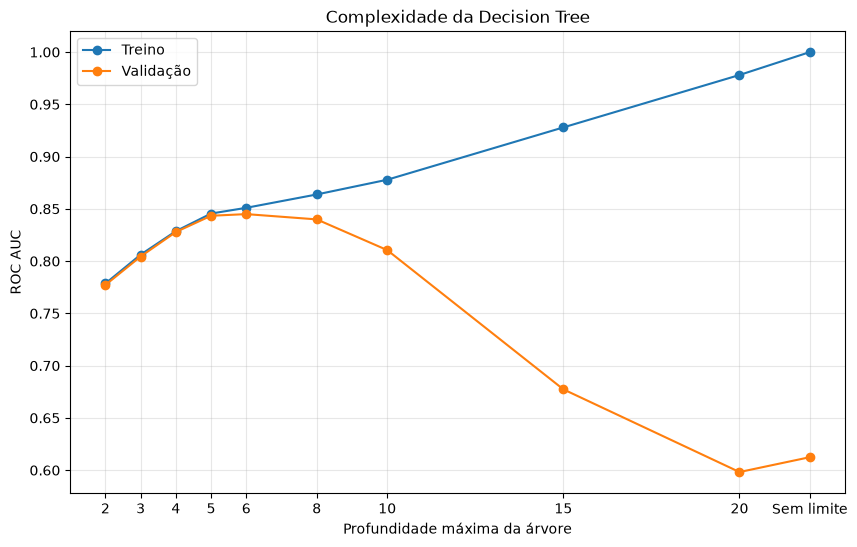

In [37]:
plt.figure(figsize=(10, 6))

plt.plot(
    df_grafico["Profundidade Gráfico"],
    df_grafico["ROC AUC Treino"],
    marker="o",
    label="Treino"
)

plt.plot(
    df_grafico["Profundidade Gráfico"],
    df_grafico["ROC AUC Validação"],
    marker="o",
    label="Validação"
)

plt.xlabel("Profundidade máxima da árvore")
plt.ylabel("ROC AUC")
plt.title("Complexidade da Decision Tree")

plt.xticks(
    [2, 3, 4, 5, 6, 8, 10, 15, 20, 22],
    ["2", "3", "4", "5", "6", "8", "10", "15", "20", "Sem limite"]
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### Interpretação da curva de complexidade

A curva evidencia o efeito da complexidade da árvore sobre sua capacidade de generalização.

Nas menores profundidades, o desempenho de treino e validação aumenta de forma semelhante, indicando que o aumento da complexidade permite ao modelo capturar informações relevantes dos dados.

A partir de aproximadamente `max_depth=6`, as curvas começam a se afastar. O ROC AUC de treino continua aumentando, enquanto o ROC AUC de validação começa a diminuir.

Esse comportamento caracteriza o aumento do overfitting: árvores mais profundas ajustam-se cada vez melhor aos dados utilizados no treinamento, mas apresentam pior capacidade de generalização.

Entre as profundidades avaliadas, `max_depth=6` apresentou o maior ROC AUC médio de validação (0,8450), embora o resultado seja muito próximo ao obtido com `max_depth=5` (0,8434).

#### 10.3.1 Refinamento da profundidade

Como os melhores resultados de validação ocorreram próximos de `max_depth=6`, será realizada uma comparação pontual entre as profundidades 5, 6, 7 e 8.

Além da média do ROC AUC, será observado o desvio-padrão entre os 5 folds para avaliar a estabilidade dos resultados.

In [38]:
profundidades_refino = [5, 6, 7, 8]

resultados_refino = []

for profundidade in profundidades_refino:

    arvore_refino = DecisionTreeClassifier(
        max_depth=profundidade,
        random_state=42
    )

    pipeline_refino = Pipeline(
        steps=[
            ("preparo", preparo),
            ("imputacao", imputacao),
            ("modelo", arvore_refino),
        ]
    )

    resultado = cross_validate(
        pipeline_refino,
        X_treino,
        y_treino,
        cv=cv,
        scoring="roc_auc"
    )

    resultados_refino.append({
        "max_depth": profundidade,
        "ROC AUC Médio": resultado["test_score"].mean(),
        "ROC AUC Desvio": resultado["test_score"].std()
    })

df_refino = pd.DataFrame(resultados_refino)

df_refino.round(4)

,max_depth,ROC AUC Médio,ROC AUC Desvio
0,5,0.8434,0.0038
1,6,0.8450,0.0029
2,7,0.8451,0.0043
3,8,0.8399,0.0039


#### Resultado do refinamento

As profundidades 6 e 7 apresentaram resultados praticamente equivalentes, com ROC AUC médio de 0,8450 e 0,8451, respectivamente.

A diferença entre esses resultados é muito pequena em relação à própria variação observada entre os folds, não sendo suficiente para afirmar que a profundidade 7 seja efetivamente superior à profundidade 6.

A análise indica que a região entre 5 e 7 níveis apresenta bom equilíbrio entre capacidade de aprendizado e generalização.

O objetivo desta análise não é realizar uma otimização exaustiva dos hiperparâmetros da Decision Tree, mas compreender o efeito da complexidade sobre o desempenho do modelo.

### 10.4 Visualização de uma árvore de decisão

Para compreender visualmente como uma Decision Tree realiza suas classificações, será treinada uma árvore com `max_depth=3`.

A profundidade 3 foi escolhida apenas para facilitar a visualização das regras e dos nós da árvore. Ela não representa necessariamente a configuração de melhor desempenho encontrada anteriormente.

**Passo 1 - criar a árvore**

In [39]:
arvore_visual = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

pipeline_visual = Pipeline(
    steps=[
        ("preparo", preparo),
        ("imputacao", imputacao),
        ("modelo", arvore_visual),
    ]
)

**Passo 2 - treinar**

In [40]:
pipeline_visual.fit(
    X_treino,
    y_treino
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparo', ...), ('imputacao', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['idade','renda_mensal','dependentes',...,'atrasos_30_59_dias', 'atrasos_60_89_dias','atrasos_90_mais_dias']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...x783d12b0be20>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


**Passo 3 - Obter os nomes das variáveis**

In [41]:
nomes_variaveis = (
    pipeline_visual
    .named_steps["imputacao"]
    .get_feature_names_out()
)

nomes_variaveis

array(['renda_mensal', 'dependentes', 'renda_por_dependente',
       'sobra_caixa', 'idade', 'uso_limite_rotativo', 'razao_divida',
       'linhas_credito_abertas', 'financiamentos_imobiliarios',
       'atrasos_30_59_dias', 'atrasos_60_89_dias', 'atrasos_90_mais_dias',
       'renda_estimada', 'dependentes_estimados', 'atrasos_96_98'],
      dtype=object)

**Passo 4 - Desenhar a árvore**

In [42]:
from sklearn.tree import plot_tree

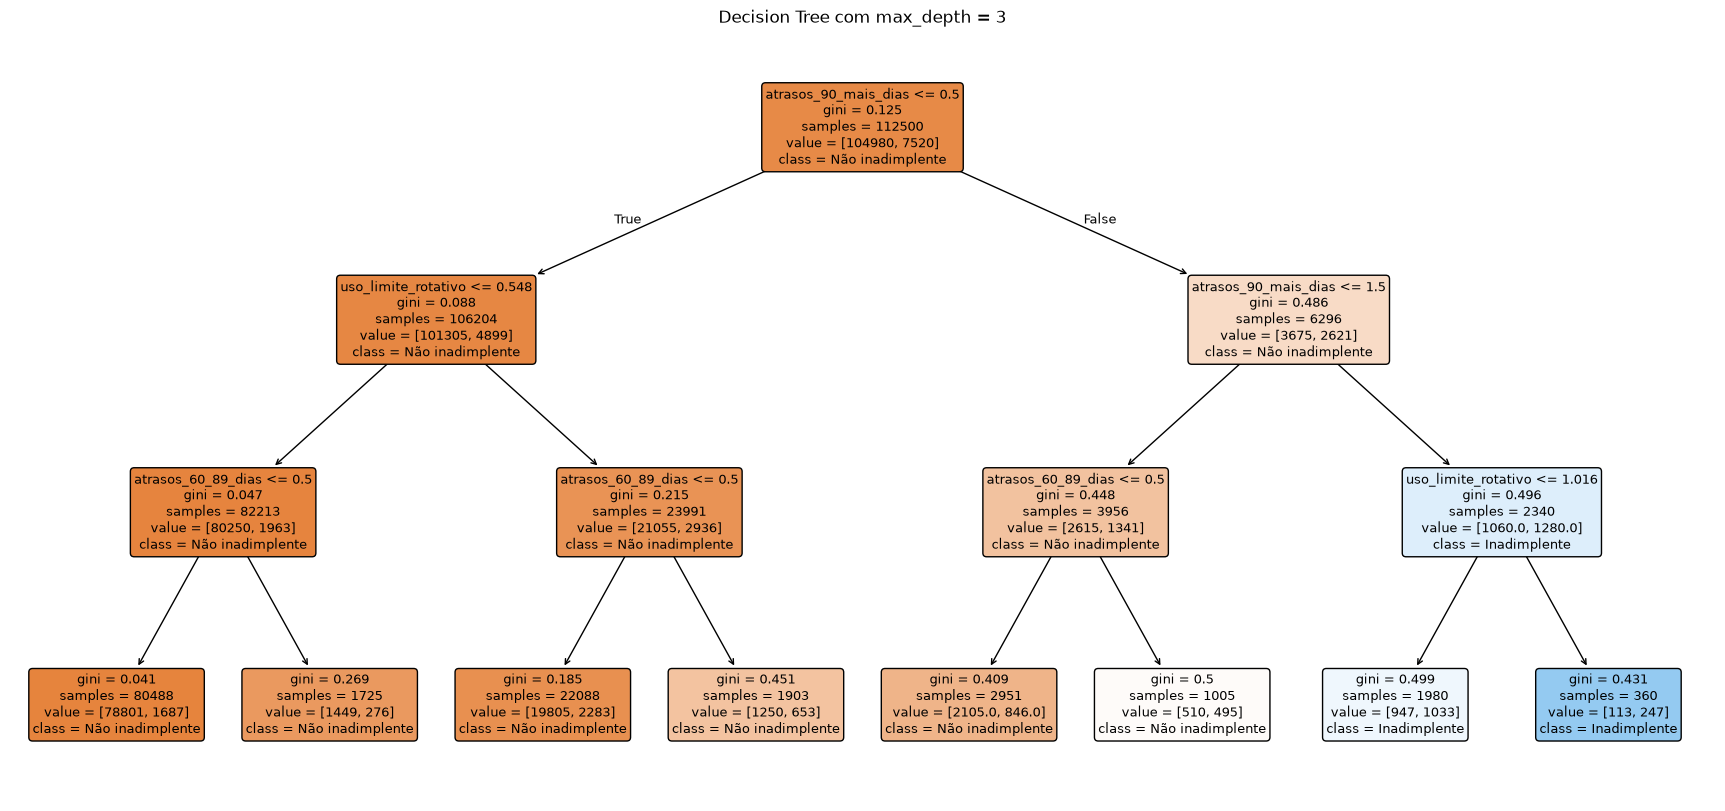

In [43]:
plt.figure(figsize=(22, 10))

plot_tree(
    pipeline_visual.named_steps["modelo"],
    feature_names=nomes_variaveis,
    class_names=["Não inadimplente", "Inadimplente"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree com max_depth = 3")
plt.show()

Agora conseguimos enxergar concretamente o que a Decision Tree está fazendo. 

A ideia principal é: a árvore começa com todos os clientes no topo e, a cada regra, divide esse grupo em dois grupos menores.

E essa árvore é especialmente interessante porque as primeiras decisões estão concentradas nas variáveis de **atraso**, que fazem bastante sentido para nosso problema.

**Como entender a árvore**

A leitura começa sempre no **nó mais alto**, chamado de **nó raiz**.

Na sua árvore, ele contém:

```text
    atrasos_90_mais_dias <= 0.5
    gini = 0.125
    samples = 112500
    value = [104980, 7520]
    class = Não inadimplente
 ```


#### Regra 1 — `atrasos_90_mais_dias <= 0.5`

Esta é a **primeira pergunta feita pela árvore**.

Ela pega os 112.500 registros do treino e verifica:

```text
    atrasos_90_mais_dias <= 0,5 ?
```
A partir daí existem dois caminhos:
```text

                    atrasos_90_mais_dias <= 0,5
                              │
                    ┌─────────┴─────────┐
                    │                   │
                  True                False
                    │                   │
                 esquerda            direita
```
Essa convenção será mantida em toda a árvore:

**True → esquerda** \
**False → direita**

**O que são `samples` e `value`?**

No mesmo nó temos:
```text
  samples = 112500
  value = [104980, 7520]
```
`samples` informa quantas observações chegaram ao nó. Como estamos no início da árvore:
```text
  samples = 112500
```
representa os **112.500 registros do conjunto de treino**.

Já:
```text
  value = [104980, 7520]
```
mostra como esses registros estão distribuídos entre as duas classes:

```text
  104.980 → Não inadimplentes
    7.520 → Inadimplentes
  ────────────────────────
  112.500 → Total
```
Observe que:
```text
104980 + 7520 = 112500
```
**E `class = Não inadimplente`?**

A árvore mostra:
```text
  class = Não inadimplente
```
porque essa é a classe predominante naquele nó.

Temos:
```text
  Não inadimplentes = 104.980
  Inadimplentes     =   7.520
```
Portanto, a maioria é não inadimplente.

Isso **não significa que todos os 112.500 sejam classificados individualmente dessa forma nesse ponto**. Estamos observando a composição do nó e a classe majoritária indicada pelo gráfico.

**E o `gini = 0.125`?**

O `gini` mede o grau de **mistura das classes dentro daquele nó**.

Aqui:
```text
  gini = 0.125
```
Temos duas classes no nó, mas uma delas é muito mais frequente:
```text
104.980 Não inadimplentes
  7.520 Inadimplentes
```
Por isso o Gini é relativamente baixo.

A ideia geral é:
```text
  Gini = 0
  → nó totalmente puro
  → só existe uma classe

  Gini próximo de 0,5
  → grande mistura entre as duas classes
```
Para duas classes, `0,5` é o máximo de impureza.



**Agora aplicamos a Regra 1**

A árvore divide os 112.500 registros de acordo com:
```text
    atrasos_90_mais_dias <= 0,5
```
**Se for `True`**

Seguimos para a **esquerda** e encontramos exatamente este nó:
```text
    uso_limite_rotativo <= 0.548
    gini = 0.088
    samples = 106204
    value = [101305, 4899]
    class = Não inadimplente
```

**Se for `False`**

Seguimos para a **direita** e encontramos:
```text
    atrasos_90_mais_dias <= 1.5
    gini = 0.486
    samples = 6296
    value = [3675, 2621]
    class = Não inadimplente
```
E podemos conferir:

```text
    106204 + 6296 = 112500
```
Ou seja, **todos os registros do nó raiz foram distribuídos entre os dois ramos**.

Isso é a essência da árvore.

#### Regra 2 — Vamos primeiro pelo lado esquerdo

Vamos acompanhar apenas o caminho esquerdo para não misturar as coisas.

Depois de passar pela primeira regra como `True`, chegamos a:

```text
  uso_limite_rotativo <= 0.548
  gini = 0.088
  samples = 106204
  value = [101305, 4899]
  class = Não inadimplente
```
Agora a árvore faz uma **nova pergunta**, mas somente para essas 106.204 observações:

```text
  uso_limite_rotativo <= 0,548 ?
```
Novamente:
```text
                    uso_limite_rotativo <= 0,548
                               │
                     ┌─────────┴─────────┐
                     │                   │
                   True                False
                     │                   │
                  esquerda            direita
```
Se for `True`, a sua árvore chega ao nó:
```text
  atrasos_60_89_dias <= 0.5
  gini = 0.047
  samples = 82213
  value = [80250, 1963]
  class = Não inadimplente
```

Se for `False`, chega a:

```text
  atrasos_60_89_dias <= 0.5
  gini = 0.215
  samples = 23991
  value = [21055, 2936]
  class = Não inadimplente
```
Novamente podemos conferir:

```text
  82.213 + 23.991 = 106.204
```
Nada desapareceu. O grupo anterior simplesmente foi dividido em dois novos grupos.


#### Regra 3 — continuando pelo extremo esquerdo

Se continuarmos sempre pelo ramo `True`, chegamos a:

```text
    atrasos_60_89_dias <= 0.5
    gini = 0.047
    samples = 82213
    value = [80250, 1963]
    class = Não inadimplente
```
Essa é a terceira regra desse caminho.

Ela pergunta:
```text
    atrasos_60_89_dias <= 0,5 ?
```
Se for `True`, chegamos finalmente à folha:

```text
    gini = 0.041
    samples = 80488
    value = [78801, 1687]
    class = Não inadimplente
```
Observe que essa caixa **não possui mais nenhuma condição na primeira linha.**

Isso significa que chegamos a uma folha.

A árvore não fará outra divisão porque definimos:
```python
max_depth=3
```

Portanto, um dos caminhos completos da sua árvore é:

```text
    112.500 registros
        │
    atrasos_90_mais_dias <= 0,5
        │ True
        ↓
    106.204 registros
        │
    uso_limite_rotativo <= 0,548
        │ True
        ↓
    82.213 registros
        │
    atrasos_60_89_dias <= 0,5
        │ True
        ↓
    80.488 registros
        │
        ▼
    FOLHA

    value = [78801, 1687]
    class = Não inadimplente

```

Esse é o princípio fundamental para ler qualquer Decision Tree: **comece no topo, avalie a condição, siga para esquerda se `True` ou direita se `False`, e repita até chegar a uma folha.**

A partir daqui, podemos voltar à **Regra 1 e percorrer o lado direito**, que é particularmente interessante na sua árvore porque ali a proporção de inadimplentes aumenta bastante.

**Lado direito da árvore**

Voltamos ao nó raiz:
```text
    atrasos_90_mais_dias <= 0.5
```
Agora seguimos pelo ramo **False**, à direita.

Chegamos a:
```text
    atrasos_90_mais_dias <= 1.5
    gini = 0.486
    samples = 6296
    value = [3675, 2621]
    class = Não inadimplente
```
O primeiro ponto importante é a mudança na composição do grupo.

No nó inicial tínhamos:
```text
    value = [104980, 7520]
```
ou aproximadamente **6,7% de inadimplentes.**

Nesse novo grupo temos:
```text
    value = [3675, 2621]
```
ou aproximadamente **41,6% de inadimplentes.**

Ou seja, a primeira divisão da árvore criou um grupo à direita com uma concentração de inadimplentes muito maior.

**Próxima divisão**

A árvore pergunta:
```text
    atrasos_90_mais_dias <= 1.5
```
Se for **True**, vamos para a esquerda:
```text
    atrasos_60_89_dias <= 0.5
    gini = 0.448
    samples = 3957
    value = [2615, 1341]
    class = Não inadimplente
```
Se for **False**, vamos para a direita:
```text
    uso_limite_rotativo <= 1.016
    gini = 0.496
    samples = 2340
    value = [1060, 1280]
    class = Inadimplente
```
Aqui aparece algo novo: pela primeira vez nesse caminho, a classe majoritária passa a ser:

```text
    class = Inadimplente
```
Isso acontece porque há mais inadimplentes do que não inadimplentes nesse nó.

**Extremo direito**

Se continuarmos pelo ramo `False` da regra:

```text
    uso_limite_rotativo <= 1.016
```
chegamos à folha:
```text
    gini = 0.431
    samples = 360
    value = [113, 247]
    class = Inadimplente
```
Aqui temos:

- 113 não inadimplentes;
- 247 inadimplentes;
- 360 observações no total.

Portanto, aproximadamente:

$$ \frac{247}{360}\approx68,6\% $$

dos registros dessa folha pertencem à classe inadimplente.

Isso contrasta bastante com o nó raiz, no qual apenas cerca de **6,7%** eram inadimplentes.

**O principal aprendizado da árvore**

É isso que eu levaria desta visualização:

```text
    Todos os clientes
    inadimplência ≈ 6,7%
            │
            ↓
    árvore aplica regras
            │
            ├── encontra grupos
            │   predominantemente não inadimplentes
            │
            └── encontra grupos
                com concentração muito maior
                de inadimplentes
```
A Decision Tree está, portanto, **segmentando a população em grupos com diferentes concentrações da classe-alvo.**

E as primeiras variáveis escolhidas pela nossa árvore de profundidade 3 foram principalmente:

`atrasos_90_mais_dias`, `uso_limite_rotativo` e `atrasos_60_89_dias`.

Isso não estabelece causalidade; mostra apenas que essas variáveis foram úteis para as divisões feitas pelo modelo nessa árvore.

## 11. Random Forest

### Objetivo

Nesta etapa será avaliado o modelo Random Forest para o problema de classificação de risco de crédito.

O Random Forest combina múltiplas árvores de decisão, utilizando diferentes amostras dos dados e subconjuntos de variáveis. A combinação das árvores busca produzir um modelo mais robusto e menos sensível ao overfitting de uma única árvore.

O modelo será avaliado seguindo a mesma metodologia utilizada anteriormente:

- validação cruzada com `StratifiedKFold` de 5 folds;
- validação realizada somente sobre os dados de treino;
- ROC AUC e Acurácia como métricas da validação cruzada;
- posterior avaliação com ROC AUC, PR AUC e Acurácia.

**O conceito que precisamos entender antes do código**

Nossa Decision Tree funciona, simplificadamente, assim:
```text
    Dados
    ↓
    UMA árvore
    ↓
    Previsão
```
O Random Forest muda a estratégia:
```text

                        Dados
                        │
        ┌──────────────┼──────────────┐
        ↓              ↓              ↓
        Árvore 1       Árvore 2       Árvore 3    ... muitas árvores
        │              │              │
        └──────────────┼──────────────┘
                        ↓
                combinação das
                    previsões
                        ↓
                previsão final
```
E as árvores não são simplesmente cópias umas das outras. O Random Forest introduz aleatoriedade principalmente em **quais observações** e **quais variáveis** cada árvore utiliza durante sua construção. Isso reduz a dependência de uma única árvore e tende a diminuir a variância do modelo.

É justamente por isso que estudar primeiro a Decision Tree foi tão útil: agora o Random Forest deixa de parecer um algoritmo completamente novo. Ele é um **ensemble de árvores de decisão**.

### 11.1 Criação do modelo e do pipeline

Inicialmente será criado um modelo `RandomForestClassifier`.

O modelo será incorporado ao mesmo pipeline de preparação utilizado anteriormente, garantindo que todas as transformações dos dados sejam realizadas dentro do processo de treinamento e validação.

In [44]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

pipeline_random_forest = Pipeline(
    steps=[
        ("preparo", preparo),
        ("imputacao", imputacao),
        ("modelo", random_forest),
    ]
)

pipeline_random_forest

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparo', ...), ('imputacao', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...x783d12b0be20>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDiction

**O que definimos aqui?**

Há três parâmetros que vale entender:

`n_estimators=100` significa que o Random Forest será formado por **100 árvores de decisão.**

`random_state=42` garante reprodutibilidade. Se executarmos novamente nas mesmas condições, teremos o mesmo componente aleatório.

`n_jobs=-1` permite utilizar **todos os núcleos disponíveis do processador** para as operações que o `RandomForestClassifier` consegue paralelizar. Isso é útil porque treinar 100 árvores é bem mais trabalhoso do que treinar uma única `Decision Tree`.

Importante: neste momento **não colocamos** `max_depth`. Estamos começando com o Random Forest praticamente em sua configuração padrão, sem transportar automaticamente a profundidade encontrada no Item 10.

### 11.2 Validação cruzada do Random Forest

O Random Forest será avaliado utilizando validação cruzada com `StratifiedKFold` de 5 folds, mantendo a proporção das classes em cada divisão.

A validação será realizada exclusivamente sobre os dados de treino.

As métricas utilizadas nesta etapa serão:

- ROC AUC;
- Acurácia.

In [45]:
resultado_cv_random_forest = cross_validate(
    pipeline_random_forest,
    X_treino,
    y_treino,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "acuracia": "accuracy",
    }
)

In [46]:
roc_auc_rf_media = resultado_cv_random_forest["test_roc_auc"].mean()
roc_auc_rf_desvio = resultado_cv_random_forest["test_roc_auc"].std()

acuracia_rf_media = resultado_cv_random_forest["test_acuracia"].mean()
acuracia_rf_desvio = resultado_cv_random_forest["test_acuracia"].std()

print(f"ROC AUC médio: {roc_auc_rf_media:.4f} ± {roc_auc_rf_desvio:.4f}")
print(f"Acurácia média: {acuracia_rf_media:.4f} ± {acuracia_rf_desvio:.4f}")

ROC AUC médio: 0.8298 ± 0.0036
Acurácia média: 0.9351 ± 0.0006


### 11.2.1 Análise da profundidade do Random Forest

Antes da avaliação na base de teste, será realizada uma análise simples do parâmetro `max_depth`.

O objetivo é verificar se limitar a profundidade das árvores que compõem o Random Forest melhora sua capacidade de generalização.

Cada configuração será avaliada utilizando os mesmos 5 folds da validação cruzada e o ROC AUC médio como principal referência.

**Quais configurações vamos testar?**

Já conhecemos o resultado sem limite:

```text
    max_depth=None → ROC AUC = 0,8298
```
Então não precisamos treiná-lo novamente.

Vamos testar somente:
```text
    max_depth = 5
    max_depth = 7
    max_depth = 10
    max_depth = 15
```
São **quatro novos experimentos**. Isso deve levar algo na ordem de 1–2 minutos no seu computador, embora o tempo real possa variar.

In [47]:
profundidades_rf = [5, 7, 10, 15]

resultados_profundidade_rf = []

for profundidade in profundidades_rf:
    
    modelo_rf = RandomForestClassifier(
        n_estimators=50,
        max_depth=profundidade,
        random_state=42,
        n_jobs=-1
    )

    pipeline_rf_teste = Pipeline(
        steps=[
            ("preparo", preparo),
            ("imputacao", imputacao),
            ("modelo", modelo_rf),
        ]
    )

    resultado = cross_validate(
        pipeline_rf_teste,
        X_treino,
        y_treino,
        cv=cv,
        scoring="roc_auc"
    )

    resultados_profundidade_rf.append({
        "max_depth": profundidade,
        "ROC AUC Médio": resultado["test_score"].mean(),
        "ROC AUC Desvio": resultado["test_score"].std()
    })

df_profundidade_rf = pd.DataFrame(resultados_profundidade_rf)

df_profundidade_rf.round(4)

,max_depth,ROC AUC Médio,ROC AUC Desvio
0,5,0.8562,0.0035
1,7,0.8607,0.0033
2,10,0.8622,0.0035
3,15,0.8585,0.0043


Agora temos um resultado bem interessante. O pequeno ajuste de `max_depth` **melhorou claramente o Random Forest.**

Os resultados foram:

| `max_depth` | ROC AUC médio |     Desvio |
| ----------: | ------------: | ---------: |
|           5 |        0,8562 |     0,0035 |
|           7 |        0,8607 |     0,0033 |
|      **10** |    **0,8622** | **0,0035** |
|          15 |        0,8585 |     0,0043 |
|  Sem limite |        0,8298 |     0,0036 |


**O que aprendemos aqui?**

Existe um comportamento muito parecido com o que vimos na Decision Tree.

Sem controlar a profundidade:
```text
    ROC AUC = 0,8298
```
Quando limitamos a profundidade, o desempenho melhora:

```text
    5  → 0,8562
    7  → 0,8607
    10 → 0,8622  ← maior média observada
    15 → 0,8585
```
Depois, sem limite, cai para `0,8298`.

Isso mostra que **deixar as árvores crescerem livremente não foi a melhor estratégia para os nossos dados**.

**Vamos escolher `max_depth=10`?**

Sim, para prosseguirmos no trabalho, faz sentido usar:

```python
RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)
```

Mas com uma precisão importante: não devemos dizer que `10` é a **profundidade ótima absoluta** do Random Forest.

Podemos afirmar:

> Entre as configurações avaliadas, `max_depth=10` apresentou o maior ROC AUC médio na validação cruzada.

Isso é cientificamente mais correto.

**E uma comparação interessante**

Agora temos:
```text
    Decision Tree controlada ≈ 0,845
    Random Forest depth 10   ≈ 0,862
```
Então a situação mudou em relação ao primeiro Random Forest: após esse pequeno controle de complexidade, o Random Forest apresentou ROC AUC médio superior ao observado na análise de profundidade da Decision Tree.

#### Resultado da análise de profundidade

A limitação da profundidade das árvores melhorou o desempenho do Random Forest em relação ao modelo sem restrição de profundidade.

Entre as configurações avaliadas, `max_depth=10` apresentou o maior ROC AUC médio, com **0,8622 ± 0,0035**.

Profundidades superiores não apresentaram melhora no desempenho, e o modelo sem limite de profundidade havia obtido ROC AUC médio de 0,8298.

Dessa forma, `max_depth=10` será utilizado como configuração do Random Forest para a avaliação posterior na base de teste. Essa escolha representa o melhor resultado entre as configurações avaliadas, não necessariamente o ótimo global do modelo.

### 11.3 Avaliação do Random Forest na base de teste

Após a análise realizada por validação cruzada, será utilizado o Random Forest com `max_depth=10`, que apresentou o maior ROC AUC médio entre as configurações avaliadas.

O modelo será treinado utilizando toda a base de treino e posteriormente avaliado na base de teste.

As métricas utilizadas serão:

- ROC AUC;
- PR AUC;
- Acurácia.

In [48]:
random_forest_final = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

pipeline_random_forest_final = Pipeline(
    steps=[
        ("preparo", preparo),
        ("imputacao", imputacao),
        ("modelo", random_forest_final),
    ]
)

Agora treinamos com **todo o conjunto de treino:**

In [49]:
pipeline_random_forest_final.fit(
    X_treino,
    y_treino
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparo', ...), ('imputacao', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['idade','renda_mensal','dependentes',...,'atrasos_30_59_dias', 'atrasos_60_89_dias','atrasos_90_mais_dias']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...x783d12b0be20>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


Aqui não há mais 5 folds. É um único Random Forest treinado utilizando todo o conjunto de treino disponível.

Precisaremos de dois tipos de saída:

In [50]:
y_pred_rf = pipeline_random_forest_final.predict(X_teste)

y_proba_rf = pipeline_random_forest_final.predict_proba(X_teste)[:, 1]

A diferença é importante:

`predict()` fornece a **classe prevista**, 0 ou 1, e será usado para calcular a acurácia.

`predict_proba()` fornece probabilidades. O [:, 1] pega especificamente a probabilidade da classe 1 = **inadimplente**. Isso será usado para ROC AUC e PR AUC.

In [51]:
roc_auc_rf_teste = roc_auc_score(
    y_teste,
    y_proba_rf
)

pr_auc_rf_teste = average_precision_score(
    y_teste,
    y_proba_rf
)

acuracia_rf_teste = accuracy_score(
    y_teste,
    y_pred_rf
)

print(f"ROC AUC: {roc_auc_rf_teste:.4f}")
print(f"PR AUC: {pr_auc_rf_teste:.4f}")
print(f"Acurácia: {acuracia_rf_teste:.4f}")

ROC AUC: 0.8653
PR AUC: 0.4041
Acurácia: 0.9369


#### Resultado final do Random Forest

O Random Forest com 50 árvores e `max_depth=10` apresentou na base de teste:

- **ROC AUC:** 0,8653
- **PR AUC:** 0,4041
- **Acurácia:** 0,9369

O ROC AUC obtido na base de teste ficou próximo ao resultado médio da validação cruzada (0,8622 ± 0,0035), indicando consistência entre o desempenho observado durante a validação e em dados não utilizados na escolha da configuração.

O PR AUC de 0,4041 representa uma melhora expressiva em relação à prevalência da classe positiva e ao resultado do modelo Dummy, sendo uma métrica especialmente relevante devido ao desbalanceamento da variável-alvo.

A acurácia também foi superior à do modelo Dummy, porém sua interpretação isolada permanece limitada devido ao desbalanceamento das classes.

## 12. XGBoost

### Objetivo

Nesta etapa será avaliado o modelo XGBoost para o problema de classificação de risco de crédito.

O XGBoost é um algoritmo baseado em árvores que utiliza a técnica de boosting. Diferentemente do Random Forest, que combina várias árvores construídas de forma mais independente, no boosting as árvores são construídas sequencialmente, de modo que cada nova árvore busca melhorar os erros do conjunto anterior.

O modelo será avaliado seguindo a mesma metodologia utilizada anteriormente:

- validação cruzada com `StratifiedKFold` de 5 folds;
- validação realizada somente sobre os dados de treino;
- ROC AUC e Acurácia como métricas da validação cruzada;
- posterior avaliação na base de teste com ROC AUC, PR AUC e Acurácia.

**O conceito principal**

No Random Forest, simplificamos a ideia assim:
```text
            ┌→ Árvore 1
    Dados ────┼→ Árvore 2
            ├→ Árvore 3
            └→ ...
                    ↓
            combinação das árvores
                    ↓
                previsão
```
No XGBoost, a lógica é diferente:
```text
  Dados
    ↓
  Árvore 1
    ↓
  observa o que precisa melhorar
    ↓
  Árvore 2
    ↓
  busca melhorar o conjunto
    ↓
  Árvore 3
    ↓
  ...
    ↓
  combinação de todas
    ↓
  previsão final
```
Portanto, guarde esta diferença:

**Random Forest**: várias árvores com aleatoriedade, depois agregadas.

**XGBoost**: árvores construídas **sequencialmente**, com cada etapa buscando melhorar o modelo formado pelas anteriores.

In [52]:
# verificando se o XGBoost está instalado
import xgboost

print("Versão do XGBoost:", xgboost.__version__)

Versão do XGBoost: 3.4.1


### 12.2 Criação do modelo e do pipeline

Nesta etapa será criado o modelo `XGBClassifier` e incorporado ao mesmo pipeline de preparação utilizado nos modelos anteriores.

Inicialmente será utilizada uma configuração de referência, antes de qualquer análise adicional de hiperparâmetros.

In [53]:
from xgboost import XGBClassifier

xgboost_modelo = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.3,
    random_state=42,
    n_jobs=-1
)

pipeline_xgboost = Pipeline(
    steps=[
        ("preparo", preparo),
        ("imputacao", imputacao),
        ("modelo", xgboost_modelo),
    ]
)

pipeline_xgboost

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparo', ...), ('imputacao', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...x783d12b0be20>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDiction

**Três parâmetros novos que precisamos entender**

Aqui `n_estimators=100` também significa **100 árvores**, mas há uma diferença fundamental em relação ao Random Forest: no XGBoost essas árvores participam de um processo **sequencial de boosting**.

`max_depth=6` limita a profundidade de cada árvore. Aqui estamos usando 6 como configuração inicial do XGBoost, **não porque a Decision Tree anterior indicou que 6 seja ideal para o XGBoost**.

E aparece um parâmetro muito importante:
```python
learning_rate=0.3
```
O `learning_rate` controla quanto cada nova árvore contribui para a correção do modelo que já vinha sendo construído. De maneira simplificada:

```text
    learning_rate maior
    → cada árvore tem maior impacto

    learning_rate menor
    → cada árvore contribui de maneira mais gradual
    → normalmente pode exigir mais árvores
```
A combinação entre `learning_rate` e `n_estimators` é uma característica importante dos modelos de boosting.

Por enquanto, não vamos otimizar nada. Primeiro queremos uma **referência inicial**, assim como fizemos com o Random Forest.

### 12.3 Validação cruzada do XGBoost

O XGBoost será avaliado utilizando validação cruzada com `StratifiedKFold` de 5 folds, mantendo a mesma metodologia aplicada aos modelos anteriores.

A validação será realizada exclusivamente sobre os dados de treino.

As métricas utilizadas serão:

- ROC AUC;
- Acurácia.

In [54]:
resultado_cv_xgboost = cross_validate(
    pipeline_xgboost,
    X_treino,
    y_treino,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "acuracia": "accuracy",
    }
)

In [55]:
for i in range(5):
    print(
        f"Fold {i+1}: "
        f"ROC AUC = {resultado_cv_xgboost['test_roc_auc'][i]:.4f} | "
        f"Acurácia = {resultado_cv_xgboost['test_acuracia'][i]:.4f}"
    )

Fold 1: ROC AUC = 0.8540 | Acurácia = 0.9359
Fold 2: ROC AUC = 0.8550 | Acurácia = 0.9343
Fold 3: ROC AUC = 0.8468 | Acurácia = 0.9358
Fold 4: ROC AUC = 0.8490 | Acurácia = 0.9346
Fold 5: ROC AUC = 0.8474 | Acurácia = 0.9344


In [56]:
roc_auc_xgb_media = resultado_cv_xgboost["test_roc_auc"].mean()
roc_auc_xgb_desvio = resultado_cv_xgboost["test_roc_auc"].std()

acuracia_xgb_media = resultado_cv_xgboost["test_acuracia"].mean()
acuracia_xgb_desvio = resultado_cv_xgboost["test_acuracia"].std()

print(f"ROC AUC médio: {roc_auc_xgb_media:.4f} ± {roc_auc_xgb_desvio:.4f}")
print(f"Acurácia média: {acuracia_xgb_media:.4f} ± {acuracia_xgb_desvio:.4f}")

ROC AUC médio: 0.8504 ± 0.0034
Acurácia média: 0.9350 ± 0.0007


**Resultado inicial do XGBoost**
```text
    ROC AUC médio: 0,8504 ± 0,0034
    Acurácia média: 0,9350 ± 0,0007
    Tempo: 6,1 s
```
Comparando com nosso Random Forest ajustado:

| Modelo                     |          ROC AUC CV |     Acurácia CV | Tempo observado |
| -------------------------- | ------------------: | --------------: | --------------: |
| Random Forest (`depth=10`) | **0,8622 ± 0,0035** |               — |        ~25,6 s |
| XGBoost inicial            |     0,8504 ± 0,0034 | 0,9350 ± 0,0007 |       **6,1 s** |

 
Então, nessa configuração inicial, o XGBoost teve ROC AUC inferior ao Random Forest, mas foi consideravelmente mais rápido no seu computador.

### 12.3.1 Análise de `learning_rate` e número de árvores

Antes da avaliação na base de teste, será realizada uma análise simples da relação entre `learning_rate` e `n_estimators`.

No XGBoost, um `learning_rate` menor reduz a contribuição individual de cada nova árvore. Por esse motivo, valores menores de `learning_rate` podem ser combinados com um número maior de árvores.

O objetivo não é realizar uma otimização exaustiva, mas verificar se um aprendizado mais gradual melhora o ROC AUC obtido na validação cruzada.

In [57]:
configuracoes_xgb = [
    {"n_estimators": 100, "learning_rate": 0.10},
    {"n_estimators": 200, "learning_rate": 0.05},
]

resultados_config_xgb = []

for config in configuracoes_xgb:

    modelo_xgb = XGBClassifier(
        n_estimators=config["n_estimators"],
        learning_rate=config["learning_rate"],
        max_depth=6,
        random_state=42,
        n_jobs=-1
    )

    pipeline_xgb_teste = Pipeline(
        steps=[
            ("preparo", preparo),
            ("imputacao", imputacao),
            ("modelo", modelo_xgb),
        ]
    )

    resultado = cross_validate(
        pipeline_xgb_teste,
        X_treino,
        y_treino,
        cv=cv,
        scoring="roc_auc"
    )

    resultados_config_xgb.append({
        "n_estimators": config["n_estimators"],
        "learning_rate": config["learning_rate"],
        "ROC AUC Médio": resultado["test_score"].mean(),
        "ROC AUC Desvio": resultado["test_score"].std()
    })

df_config_xgb = pd.DataFrame(resultados_config_xgb)

df_config_xgb.round(4)

,n_estimators,learning_rate,ROC AUC Médio,ROC AUC Desvio
0,100,0.10,0.8623,0.0038
1,200,0.05,0.8624,0.0039


Entendendo os resultados. Agora conseguimos enxergar claramente o efeito desse pequeno ajuste no XGBoost:

| Configuração | `n_estimators` | `learning_rate` |          ROC AUC CV |
| ------------ | -------------: | --------------: | ------------------: |
| Inicial      |            100 |            0,30 |     0,8504 ± 0,0034 |
| Ajustada 1   |            100 |            0,10 | **0,8623 ± 0,0038** |
| Ajustada 2   |            200 |            0,05 | **0,8624 ± 0,0039** |


**O que aprendemos?**

Reduzir o `learning_rate` trouxe uma melhora relevante:

```text
    0,8504  →  0,8623 / 0,8624
```
Porém, entre as duas novas configurações:
```text
    100 árvores + LR 0,10 → 0,8623
    200 árvores + LR 0,05 → 0,8624
```
a diferença é de apenas:
```text
    0,0001
```
Isso é insignificante diante dos próprios desvios dos folds (`±0,0038`b e `±0,0039`). Portanto, **não temos evidência de que a configuração com 200 árvores seja realmente melhor.**

E ela ainda exige o dobro de árvores.

**Qual configuração eu escolheria para continuar?**

Para o nosso projeto, faz mais sentido:
```python
XGBClassifier(
    n_estimators=100,
    learning_rate=0.10,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)
```
Ela entrega praticamente o mesmo desempenho usando apenas **100 árvores**, mantendo o modelo mais simples e computacionalmente mais econômico.

Curiosamente, chegamos agora a:
```text
    Random Forest ajustado → ROC AUC CV = 0,8622
    XGBoost ajustado       → ROC AUC CV = 0,8623
```
Ou seja, até aqui os dois estão **praticamente empatados em ROC AUC de validação cruzada**. Ainda não é hora de concluir qual é superior.

#### Resultado da análise das configurações

A redução do `learning_rate` melhorou o desempenho do XGBoost em relação à configuração inicial.

A configuração com 100 árvores e `learning_rate=0,10` apresentou ROC AUC médio de **0,8623 ± 0,0038**, enquanto a configuração com 200 árvores e `learning_rate=0,05` apresentou **0,8624 ± 0,0039**.

Como a diferença entre os dois resultados é muito pequena em relação à variação observada entre os folds, não há evidência suficiente para considerar a configuração com 200 árvores superior.

Dessa forma, será utilizada a configuração com 100 árvores e `learning_rate=0,10`, por apresentar desempenho praticamente equivalente com menor complexidade computacional.

### 12.4 Avaliação do XGBoost na base de teste

Após a análise das configurações por validação cruzada, será utilizado o XGBoost com 100 árvores, `learning_rate=0,10` e `max_depth=6`.

O modelo será treinado utilizando toda a base de treino e posteriormente avaliado na base de teste.

As métricas utilizadas serão:

- ROC AUC;
- PR AUC;
- Acurácia.

In [58]:
xgboost_final = XGBClassifier(
    n_estimators=100,
    learning_rate=0.10,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

pipeline_xgboost_final = Pipeline(
    steps=[
        ("preparo", preparo),
        ("imputacao", imputacao),
        ("modelo", xgboost_final),
    ]
)

In [59]:
pipeline_xgboost_final.fit(
    X_treino,
    y_treino
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparo', ...), ('imputacao', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['idade','renda_mensal','dependentes',...,'atrasos_30_59_dias', 'atrasos_60_89_dias','atrasos_90_mais_dias']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...x783d12b0be20>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


In [60]:
y_pred_xgb = pipeline_xgboost_final.predict(X_teste)

y_proba_xgb = pipeline_xgboost_final.predict_proba(X_teste)[:, 1]

In [61]:
roc_auc_xgb_teste = roc_auc_score(
    y_teste,
    y_proba_xgb
)

pr_auc_xgb_teste = average_precision_score(
    y_teste,
    y_proba_xgb
)

acuracia_xgb_teste = accuracy_score(
    y_teste,
    y_pred_xgb
)

print(f"ROC AUC: {roc_auc_xgb_teste:.4f}")
print(f"PR AUC: {pr_auc_xgb_teste:.4f}")
print(f"Acurácia: {acuracia_xgb_teste:.4f}")

ROC AUC: 0.8667
PR AUC: 0.3989
Acurácia: 0.9376


#### Resultado final do XGBoost

O XGBoost com 100 árvores, `learning_rate=0,10` e `max_depth=6` apresentou na base de teste:

- **ROC AUC:** 0,8667
- **PR AUC:** 0,3989
- **Acurácia:** 0,9376

O ROC AUC obtido na base de teste ficou próximo ao resultado médio observado na validação cruzada (0,8623 ± 0,0038), demonstrando consistência entre os resultados de validação e teste.

Em comparação ao Random Forest, os dois modelos apresentaram resultados bastante próximos. O XGBoost apresentou ROC AUC e acurácia ligeiramente maiores, enquanto o Random Forest apresentou PR AUC ligeiramente maior.

A comparação conjunta dos modelos será realizada posteriormente, após a avaliação de todos os algoritmos previstos.

## 13. LightGBM

### Objetivo

Nesta etapa será avaliado o modelo LightGBM para o problema de classificação de risco de crédito.

Assim como o XGBoost, o LightGBM é um algoritmo baseado em gradient boosting com árvores de decisão. Seu desenvolvimento prioriza eficiência computacional e capacidade de trabalhar com grandes volumes de dados.

O modelo será avaliado seguindo a mesma metodologia utilizada anteriormente:

- validação cruzada com `StratifiedKFold` de 5 folds;
- validação realizada somente sobre os dados de treino;
- ROC AUC e Acurácia como métricas da validação cruzada;
- posterior avaliação na base de teste com ROC AUC, PR AUC e Acurácia.

**Qual a relação entre XGBoost e LightGBM?**

Os dois pertencem à família de **gradient boosting**. Portanto, podemos manter aquela ideia:
```text
    Árvore 1
    ↓
    Árvore 2 melhora o conjunto
    ↓
    Árvore 3 melhora o conjunto
    ↓
    ...
    ↓
    Previsão final
```
Uma diferença importante está na maneira como as árvores são construídas.

De forma simplificada, o LightGBM é conhecido por uma estratégia de crescimento **leaf-wise**: ele tende a expandir a folha cuja divisão oferece maior ganho naquele momento. Isso pode tornar o aprendizado eficiente, mas também significa que parâmetros de controle da complexidade, como número de folhas e profundidade, merecem atenção.

Não precisamos aprofundar isso agora. Para nosso projeto, o principal é entender que:
```text
    Random Forest → ensemble de árvores com aleatoriedade

    XGBoost       → gradient boosting

    LightGBM      → gradient boosting com uma implementação
                    e estratégia de crescimento próprias
```

### 13.1 Verificar a instalação

Assim como o XGBoost, o LightGBM não faz parte diretamente do `scikit-learn`.

In [62]:
# verificacao de instalacao
import lightgbm

print("Versão do LightGBM:", lightgbm.__version__)

Versão do LightGBM: 4.7.0


### 13.2. Criação do modelo LightGBM

Nesta etapa será criado o modelo LightGBM utilizando uma configuração inicial simples.

Assim como nos modelos anteriores, o LightGBM será integrado ao pipeline de preparação dos dados, garantindo que as mesmas transformações sejam aplicadas durante o treinamento e a validação.

Configuração inicial:

- `n_estimators = 100`: número de árvores construídas pelo modelo.
- `learning_rate = 0.1`: controla a contribuição de cada nova árvore.
- `random_state = 42`: garante reprodutibilidade.
- `n_jobs = -1`: permite utilizar os núcleos disponíveis do processador.
- `verbosity = -1`: evita a exibição de mensagens internas do LightGBM durante o treinamento.

In [63]:
from lightgbm import LGBMClassifier

lightgbm_modelo = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

pipeline_lightgbm = Pipeline(
    steps=[
        ("preparo", preparo),
        ("imputacao", imputacao),
        ("modelo", lightgbm_modelo),
    ]
)

pipeline_lightgbm

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparo', ...), ('imputacao', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...x783d12b0be20>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDiction

Uma diferença importante em relação ao XGBoost: por enquanto **não vamos definir** `max_depth`. O LightGBM controla a complexidade principalmente por outros parâmetros, especialmente `num_leaves`. Vamos primeiro observar seu desempenho inicial e depois decidir se vale fazer um pequeno ajuste, como fizemos com Random Forest e XGBoost.

### 13.3. Validação cruzada do LightGBM

O LightGBM será avaliado utilizando o mesmo procedimento aplicado aos modelos anteriores:

- StratifiedKFold com 5 folds;
- somente os dados de treino;
- ROC-AUC e acurácia como métricas.

Manter o mesmo procedimento de validação permite comparar os modelos sob as mesmas condições.

In [64]:
resultado_cv_lightgbm = cross_validate(
    pipeline_lightgbm,
    X_treino,
    y_treino,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "acuracia": "accuracy",
    }
)

roc_auc_lgbm = resultado_cv_lightgbm["test_roc_auc"]
acuracia_lgbm = resultado_cv_lightgbm["test_acuracia"]

for fold in range(5):
    print(
        f"Fold {fold + 1}: "
        f"ROC-AUC = {roc_auc_lgbm[fold]:.4f} | "
        f"Acurácia = {acuracia_lgbm[fold]:.4f}"
    )

print()
print(
    f"ROC-AUC médio: {roc_auc_lgbm.mean():.4f} "
    f"± {roc_auc_lgbm.std():.4f}"
)
print(
    f"Acurácia média: {acuracia_lgbm.mean():.4f} "
    f"± {acuracia_lgbm.std():.4f}"
)

Fold 1: ROC-AUC = 0.8655 | Acurácia = 0.9372
Fold 2: ROC-AUC = 0.8666 | Acurácia = 0.9364
Fold 3: ROC-AUC = 0.8571 | Acurácia = 0.9378
Fold 4: ROC-AUC = 0.8602 | Acurácia = 0.9371
Fold 5: ROC-AUC = 0.8584 | Acurácia = 0.9367

ROC-AUC médio: 0.8616 ± 0.0038
Acurácia média: 0.9370 ± 0.0005


O LightGBM apresentou:

- ROC-AUC médio: 0.8616 ± 0.0038
- Acurácia média: 0.9370 ± 0.0005
- Tempo: aproximadamente 5,5 segundos

O resultado é bastante estável entre os 5 folds. Além disso, já está na mesma região que encontramos com os modelos ajustados anteriormente: Random Forest ficou em aproximadamente `0.8622` de ROC-AUC e XGBoost em `0.8623`.

Antes de usar a base de teste, vale fazer com o LightGBM o mesmo raciocínio que fizemos nos outros modelos: **um pequeno ajuste usando somente validação cruzada**.

Como o LightGBM cresce árvores de maneira diferente, um parâmetro especialmente importante é o `num_leaves`, que limita quantas folhas cada árvore pode ter. Em termos intuitivos:

> poucas folhas → modelo mais simples \
> muitas folhas → modelo mais complexo

Sugiro testarmos apenas 3 valores, por exemplo `15`, `31` (padrão) e `63`. Assim aprendemos o efeito do parâmetro sem transformar nosso trabalho em uma busca extensa de hiperparâmetros.

#### 13.3.1. Análise do número de folhas (`num_leaves`)

No LightGBM, o parâmetro `num_leaves` controla o número máximo de folhas de cada árvore e influencia diretamente a complexidade do modelo.

Serão avaliados três valores:

- 15 folhas: modelo mais simples;
- 31 folhas: valor padrão do LightGBM;
- 63 folhas: modelo mais complexo.

Todos os demais parâmetros serão mantidos constantes. A comparação será realizada somente nos dados de treino, utilizando o mesmo StratifiedKFold com 5 folds e ROC-AUC como métrica.

O objetivo não é realizar uma busca extensa de hiperparâmetros, mas verificar se uma pequena alteração na complexidade produz ganho relevante de desempenho.

In [65]:
valores_num_leaves = [15, 31, 63]

resultados_leaves = []

for num_leaves in valores_num_leaves:

    modelo = LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        num_leaves=num_leaves,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    pipeline = Pipeline(
        steps=[
            ("preparo", preparo),
            ("imputacao", imputacao),
            ("modelo", modelo),
        ]
    )

    resultado = cross_validate(
        pipeline,
        X_treino,
        y_treino,
        cv=cv,
        scoring="roc_auc"
    )

    media = resultado["test_score"].mean()
    desvio = resultado["test_score"].std()

    resultados_leaves.append(
        {
            "num_leaves": num_leaves,
            "roc_auc_medio": media,
            "desvio_padrao": desvio
        }
    )

df_resultados_leaves = pd.DataFrame(resultados_leaves)

df_resultados_leaves

,num_leaves,roc_auc_medio,desvio_padrao
0,15,0.863537,0.003888
1,31,0.861551,0.003838
2,63,0.858072,0.003866


**Conclusão:** O melhor resultado entre as configurações avaliadas foi obtido com `num_leaves=15`, com ROC-AUC médio de aproximadamente 0,8635.

O aumento do número de folhas não trouxe melhoria de desempenho. Pelo contrário, o ROC-AUC diminuiu à medida que a complexidade aumentou.

Dessa forma, `num_leaves=15` será utilizado na configuração final do LightGBM. Essa escolha foi realizada exclusivamente com base na validação cruzada dos dados de treino, preservando a base de teste para a avaliação final.

### 13.4. Treinamento final e avaliação do LightGBM

Após a validação cruzada, foi selecionada a configuração com `num_leaves=15`.

O modelo será agora treinado utilizando toda a base de treino e, em seguida, avaliado na base de teste.

Serão calculadas as três métricas definidas para o projeto:

- ROC-AUC;
- PR-AUC;
- Acurácia.

A base de teste não foi utilizada na escolha da configuração do modelo, sendo reservada para esta avaliação final.

In [66]:
lightgbm_final = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    num_leaves=15,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

pipeline_lightgbm_final = Pipeline(
    steps=[
        ("preparo", preparo),
        ("imputacao", imputacao),
        ("modelo", lightgbm_final),
    ]
)

# Treinamento em toda a base de treino
pipeline_lightgbm_final.fit(X_treino, y_treino)

# Previsões na base de teste
y_pred_lgbm = pipeline_lightgbm_final.predict(X_teste)
y_proba_lgbm = pipeline_lightgbm_final.predict_proba(X_teste)[:, 1]

# Métricas
roc_auc_lgbm_teste = roc_auc_score(y_teste, y_proba_lgbm)
pr_auc_lgbm_teste = average_precision_score(y_teste, y_proba_lgbm)
acuracia_lgbm_teste = accuracy_score(y_teste, y_pred_lgbm)

print(f"ROC-AUC:  {roc_auc_lgbm_teste:.4f}")
print(f"PR-AUC:   {pr_auc_lgbm_teste:.4f}")
print(f"Acurácia: {acuracia_lgbm_teste:.4f}")

ROC-AUC:  0.8680
PR-AUC:   0.4061
Acurácia: 0.9372


### Conclusão do LightGBM

Após uma análise simples do parâmetro `num_leaves`, foi selecionado o valor 15, que apresentou ROC-AUC médio de aproximadamente 0,8635 na validação cruzada.

O modelo final, treinado em toda a base de treino, apresentou na base de teste:

- ROC-AUC: 0,8680
- PR-AUC: 0,4061
- Acurácia: 0,9372

O ROC-AUC obtido no teste ficou próximo ao observado durante a validação cruzada, indicando estabilidade do desempenho em dados não utilizados no treinamento.

Com isso, concluímos a avaliação individual do LightGBM.

## 14. Comparação final dos modelos

### 14.1. Padronização das configurações finais

Antes da comparação final, serão definidas as configurações selecionadas durante a etapa de modelagem.

A seleção dos hiperparâmetros foi realizada utilizando somente os dados de treino e validação cruzada. A base de teste não foi utilizada para escolher as configurações.

Configurações selecionadas:

- Dummy: estratégia `prior`;
- Decision Tree: `max_depth=6`;
- Random Forest: 50 árvores e `max_depth=10`;
- XGBoost: 100 árvores, `learning_rate=0.10` e `max_depth=6`;
- LightGBM: 100 árvores, `learning_rate=0.10` e `num_leaves=15`.

Para garantir uma comparação consistente, os modelos selecionados serão novamente avaliados por validação cruzada utilizando os mesmos 5 folds e as mesmas métricas: ROC-AUC e acurácia.

In [67]:
modelos_finais = {
    "Dummy": DummyClassifier(
        strategy="prior"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=50,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.10,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=100,
        learning_rate=0.10,
        num_leaves=15,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
}

### 14.2. Validação cruzada padronizada dos modelos finais

Os cinco modelos finais serão avaliados utilizando exatamente o mesmo procedimento:

- somente a base de treino;
- StratifiedKFold com 5 folds;
- ROC-AUC e acurácia como métricas;
- mesmo pipeline de preparação e imputação.

Essa avaliação permite comparar os modelos de forma consistente, evitando misturar resultados obtidos com configurações diferentes ao longo dos experimentos.

In [68]:
resultados_cv_finais = []

for nome, modelo in modelos_finais.items():

    pipeline_modelo = Pipeline(
        steps=[
            ("preparo", preparo),
            ("imputacao", imputacao),
            ("modelo", modelo),
        ]
    )

    resultado = cross_validate(
        pipeline_modelo,
        X_treino,
        y_treino,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "acuracia": "accuracy"
        }
    )

    resultados_cv_finais.append({
        "Modelo": nome,
        "ROC-AUC médio": resultado["test_roc_auc"].mean(),
        "ROC-AUC desvio": resultado["test_roc_auc"].std(),
        "Acurácia média": resultado["test_acuracia"].mean(),
        "Acurácia desvio": resultado["test_acuracia"].std()
    })

df_cv_finais = pd.DataFrame(resultados_cv_finais)

df_cv_finais

,Modelo,ROC-AUC médio,ROC-AUC desvio,Acurácia média,Acurácia desvio
0,Dummy,0.500000,0.000000,0.933156,0.000000
1,Decision Tree,0.844962,0.002925,0.935084,0.000300
2,Random Forest,0.862156,0.003504,0.936667,0.000568
3,XGBoost,0.862300,0.003765,0.937013,0.000286
4,LightGBM,0.863537,0.003888,0.937209,0.000294


**Interpretação da validação cruzada**

O Dummy apresentou ROC-AUC de 0,50, confirmando que sua elevada acurácia decorre principalmente do desbalanceamento da variável alvo e não de capacidade discriminatória.

A Decision Tree com profundidade controlada apresentou melhora expressiva em relação à árvore sem restrição, evidenciando a importância do controle de complexidade para reduzir o overfitting.

Random Forest, XGBoost e LightGBM apresentaram resultados bastante próximos, com ROC-AUC médio em torno de 0,86 e baixa variação entre os folds.

O LightGBM apresentou o maior ROC-AUC médio entre as configurações avaliadas, porém a diferença em relação ao Random Forest e ao XGBoost é pequena quando comparada à própria variabilidade observada na validação cruzada. Portanto, os três modelos apresentaram desempenho semelhante nesta etapa.

### 14.3. Comparação final na base de teste

Após a seleção das configurações utilizando exclusivamente a validação cruzada, os cinco modelos finais serão treinados em toda a base de treino e avaliados na base de teste.

Serão utilizadas as três métricas definidas para o projeto:

- ROC-AUC;
- PR-AUC;
- Acurácia.

Essa etapa permite comparar o desempenho dos modelos em dados que não foram utilizados durante o treinamento nem na escolha das configurações.

In [69]:
resultados_teste_finais = []

for nome, modelo in modelos_finais.items():

    pipeline_modelo = Pipeline(
        steps=[
            ("preparo", preparo),
            ("imputacao", imputacao),
            ("modelo", modelo),
        ]
    )

    # Treinamento em toda a base de treino
    pipeline_modelo.fit(X_treino, y_treino)

    # Previsões
    y_pred = pipeline_modelo.predict(X_teste)
    y_proba = pipeline_modelo.predict_proba(X_teste)[:, 1]

    # Métricas
    resultados_teste_finais.append({
        "Modelo": nome,
        "ROC-AUC": roc_auc_score(y_teste, y_proba),
        "PR-AUC": average_precision_score(y_teste, y_proba),
        "Acurácia": accuracy_score(y_teste, y_pred)
    })

df_teste_finais = pd.DataFrame(resultados_teste_finais)

df_teste_finais

,Modelo,ROC-AUC,PR-AUC,Acurácia
0,Dummy,0.500000,0.066827,0.933173
1,Decision Tree,0.844087,0.350405,0.935840
2,Random Forest,0.865256,0.404080,0.936853
3,XGBoost,0.866742,0.398950,0.937600
4,LightGBM,0.868026,0.406104,0.937200


**Interpretação dos resultados na base de teste**

O Dummy apresentou acurácia elevada devido ao desbalanceamento da variável alvo, porém ROC-AUC de 0,50 e PR-AUC próxima à prevalência da classe positiva, confirmando sua utilização apenas como baseline.

A Decision Tree com profundidade controlada apresentou desempenho substancialmente superior à árvore sem restrição avaliada anteriormente. O ROC-AUC de 0,8441 no teste ficou muito próximo ao observado na validação cruzada, indicando melhora na capacidade de generalização após o controle de complexidade.

Random Forest, XGBoost e LightGBM apresentaram resultados próximos nas três métricas. Entre as configurações avaliadas, o LightGBM apresentou ROC-AUC de 0,8680 e PR-AUC de 0,4061, enquanto o XGBoost apresentou a maior acurácia, com 0,9376.

As diferenças entre esses três modelos são pequenas. Portanto, os resultados indicam desempenho semelhante entre os modelos de ensemble, sem evidência de uma diferença ampla de desempenho apenas com base nessas métricas.

**Um ponto importante antes de encerrarmos a modelagem**

Nosso problema de negócio tem uma informação que ainda **não entrou de verdade na decisão operacional**:

> um falso negativo custa 10 vezes mais que um falso positivo.

Até aqui avaliamos a capacidade dos modelos de gerar bons scores, com ROC-AUC e PR-AUC, e a classificação produzida pelo limiar padrão. Mas, em risco de crédito, o próximo raciocínio importante é justamente o threshold (ponto de corte).

Um cliente com probabilidade prevista de `0,42`, por exemplo, é classificado como `0` usando threshold `0,50`. Porém, se falso negativo custa 10× mais, talvez `0,50` não seja o ponto de corte adequado.

Então eu sugiro que o próximo item seja:

**Matriz de confusão, falso positivo, falso negativo e definição do threshold considerando o custo FN = 10 × FP.**

Isso conecta a modelagem diretamente ao problema de negócio que definimos no início do projeto.

## 15. Matriz de Confusão e análise dos erros

Até aqui, os modelos foram avaliados principalmente por ROC-AUC, PR-AUC e acurácia.

Entretanto, no problema de crédito também é importante compreender quais tipos de erros o modelo está cometendo.

A matriz de confusão permite separar as previsões em quatro situações:

- Verdadeiro Negativo (TN): cliente adimplente corretamente classificado como adimplente;
- Falso Positivo (FP): cliente adimplente classificado como inadimplente;
- Falso Negativo (FN): cliente inadimplente classificado como adimplente;
- Verdadeiro Positivo (TP): cliente inadimplente corretamente classificado como inadimplente.

Neste projeto, o falso negativo possui especial importância, pois foi definido que seu custo é 10 vezes maior que o custo de um falso positivo.

Inicialmente será utilizado o threshold padrão de 0,50.

Antes do código: como ler a matriz

No nosso projeto:
```text
                        PREVISTO
                      0          1
    REAL  0           TN         FP
          1           FN         TP
```
O erro mais preocupante para o negócio é:
```text
    FN = Falso Negativo
```
Isso representa um cliente que realmente se tornou inadimplente (`1`), mas que o modelo classificou como não inadimplente (`0`).

Como definimos:
```text
    Custo FN = 10 × custo FP
```
não basta procurar a maior acurácia. Queremos observar especialmente quantos FN estamos produzindo.

In [70]:
from sklearn.metrics import confusion_matrix

matriz_confusao_lgbm = confusion_matrix(
    y_teste,
    y_pred_lgbm
)

matriz_confusao_lgbm

array([[34670,   324],
       [ 2031,   475]])

Agora conseguimos enxergar claramente um problema que ROC-AUC e acurácia sozinhos não mostram.

Sua matriz foi:
```text
	[[34670   324]
	[ 2031   475]]
```
Ela deve ser lida assim:

|            |  Previsto 0 | Previsto 1 |
| ---------- | ----------: | ---------: |
| **Real 0** | TN = 34.670 |   FP = 324 |
| **Real 1** |  FN = 2.031 |   TP = 475 |


Vamos interpretar com cuidado.

**TN = 34.670**: eram clientes adimplentes (`0`) e o modelo corretamente previu `0`.

**FP = 324**: eram clientes adimplentes (`0`), mas o modelo previu inadimplência (`1`). É um erro.

**FN = 2.031**: eram clientes que realmente ficaram inadimplentes (`1`), mas o modelo previu que seriam adimplentes (`0`). **Esse é justamente o erro que definimos como mais caro para o negócio**.

**TP = 475**: eram clientes inadimplentes (`1`) e o modelo conseguiu identificá-los corretamente.

E aqui aparece algo muito importante. Dos:
```text
	2.031 + 475 = 2.506
```
clientes realmente inadimplentes, o modelo identificou corretamente apenas:
```text
	475 / 2.506 ≈ 18,95%
```
Ou seja, usando o **threshold padrão de 0,50**, o LightGBM está deixando passar aproximadamente **81% dos inadimplentes**.

Isso não contradiz o ROC-AUC de `0,868`. O ROC-AUC avalia a capacidade do modelo de ordenar/separar os clientes por risco ao longo de vários thresholds. Já a matriz de confusão depende de um threshold específico, que neste caso é `0,50`.

E agora entra diretamente nossa regra de negócio:
```text
	Custo(FN) = 10 × Custo(FP)
```
Com threshold `0,50`, temos:
```text
	FP = 324
	FN = 2.031
```
Se atribuirmos custo `1` para cada FP e `10` para cada FN, apenas para criar uma unidade comparável:
```text
	Custo = FP × 1 + FN × 10

	Custo = 324 + (2.031 × 10)

	Custo = 20.634
```
Isso nos dá uma excelente motivação para o próximo passo: **reduzir o threshold**. Ao reduzi-lo, o modelo tende a classificar mais clientes como `1`. Com isso, esperamos **diminuir FN**, embora provavelmente aumentemos FP.

O objetivo, portanto, não será simplesmente encontrar o **threshold** com maior acurácia. Será procurar um ponto de corte que considere explicitamente:

**FN custando 10 vezes FP.**

### 15.1. Análise do custo em diferentes thresholds

O threshold padrão de 0,50 resultou em grande quantidade de falsos negativos (FN).

Como foi definido no entendimento do negócio que um falso negativo possui custo 10 vezes maior que um falso positivo, será analisado o impacto de diferentes thresholds sobre esses dois tipos de erro.

Para fins de comparação, será utilizada a seguinte função de custo:

Custo = (10 × FN) + (1 × FP)

Reduzir o threshold tende a diminuir a quantidade de falsos negativos, porém aumenta a quantidade de falsos positivos.

O objetivo desta análise é identificar o threshold que minimiza o custo total definido para o problema.

In [71]:
thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.45, 0.50
]

resultados_threshold = []

for threshold in thresholds:

    y_pred_threshold = (y_proba_lgbm >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_teste,
        y_pred_threshold
    ).ravel()

    custo = (10 * fn) + fp

    resultados_threshold.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Custo": custo
    })

df_threshold = pd.DataFrame(resultados_threshold)

df_threshold

,Threshold,TN,FP,FN,TP,Custo
0,0.05,25646,9348,410,2096,13448
1,0.10,30580,4414,793,1713,12344
2,0.15,32371,2623,1054,1452,13163
3,0.20,33103,1891,1231,1275,14201
4,0.25,33527,1467,1367,1139,15137
5,0.30,33854,1140,1499,1007,16130
6,0.35,34165,829,1657,849,17399
7,0.40,34369,625,1782,724,18445
8,0.45,34537,457,1893,613,19387
9,0.50,34670,324,2031,475,20634


Agora ficou muito claro o efeito do **threshold**. O menor custo entre os valores testados ocorreu em **0,10**:

| Threshold |        FP |      FN |    TP |      Custo |
| --------: | --------: | ------: | ----: | ---------: |
|      0,05 |     9.348 | **410** | 2.096 |     13.448 |
|  **0,10** | **4.414** | **793** | 1.713 | **12.344** |
|      0,15 |     2.623 |   1.054 | 1.452 |     13.163 |
|      0,20 |     1.891 |   1.231 | 1.275 |     14.201 |
|      0,50 |       324 |   2.031 |   475 |     20.634 |


O comportamento é exatamente o esperado. Ao baixar o threshold de `0,50` para `0,10`, passamos a classificar mais clientes como inadimplentes. Com isso, os falsos positivos aumentam de `324` para `4.414`, mas os falsos negativos caem de `2.031` para `793`.

Como cada FN custa dez vezes um FP, essa troca é vantajosa segundo a função de custo definida:
```text
    Threshold 0,50 → custo = 20.634
    Threshold 0,10 → custo = 12.344
```
Isso representa uma redução de aproximadamente **40,2% no custo teórico** em relação ao threshold padrão.

Mas há um detalhe metodológico importante: **não devemos declarar 0,10 como threshold final ainda**. Nossa busca foi grosseira, de `0,05` em `0,05`. O ponto de menor custo pode estar, por exemplo, em `0,08`, `0,09`, `0,11` etc.

Além disso, para uma metodologia mais rigorosa, o threshold operacional idealmente deve ser escolhido usando **treino/validação**, e o teste deve permanecer para avaliação final. Como já exploramos thresholds no teste, podemos tratar esta parte como uma análise didática do projeto e registrar essa limitação.

**Interpretação**

A redução do threshold provocou uma troca entre falsos positivos e falsos negativos.

Com o threshold padrão de 0,50, foram observados 2.031 falsos negativos e 324 falsos positivos, resultando em custo de 20.634 unidades.

Entre os thresholds inicialmente avaliados, o menor custo ocorreu em 0,10, com 793 falsos negativos e 4.414 falsos positivos, resultando em custo de 12.344 unidades.

Considerando a função de custo definida para o negócio, na qual um falso negativo custa 10 vezes mais que um falso positivo, a redução do threshold mostrou-se relevante para reduzir o custo associado aos erros de classificação.

Entretanto, a análise inicial utilizou intervalos de 0,05. Portanto, será realizado um refinamento na região próxima de 0,10 antes de analisar o ponto de corte em maior detalhe.

**Conclusão da análise de threshold**

A análise demonstrou que o threshold padrão de 0,50 não é adequado quando se considera a diferença de custo entre falsos negativos e falsos positivos.

Entre os thresholds avaliados, o valor de 0,10 apresentou o menor custo total, reduzindo o custo de 20.634 unidades, observado com threshold 0,50, para 12.344 unidades.

Essa redução ocorre porque o threshold menor permite identificar uma quantidade maior de clientes inadimplentes, reduzindo os falsos negativos, embora aumente os falsos positivos.

Não foi realizada uma busca mais granular pelo threshold ótimo, pois o objetivo desta etapa é demonstrar o impacto do ponto de corte sobre o custo do negócio, e não realizar uma otimização exaustiva desse hiperparâmetro.

### 15.2. Precision e Recall em diferentes thresholds

Para complementar a análise do custo, serão comparados os thresholds 0,50 e 0,10 utilizando Precision e Recall.

- **Precision:** entre os clientes classificados como inadimplentes, indica a proporção que realmente ficou inadimplente.
- **Recall:** entre todos os clientes que realmente ficaram inadimplentes, indica a proporção identificada pelo modelo.

Como o falso negativo possui custo 10 vezes maior que o falso positivo, o Recall possui especial importância neste problema, pois mede diretamente a capacidade de identificar os clientes que efetivamente se tornaram inadimplentes.

In [72]:
from sklearn.metrics import precision_score, recall_score

resultados_precision_recall = []

for threshold in [0.50, 0.10]:

    y_pred_threshold = (y_proba_lgbm >= threshold).astype(int)

    precision = precision_score(y_teste, y_pred_threshold)
    recall = recall_score(y_teste, y_pred_threshold)

    tn, fp, fn, tp = confusion_matrix(
        y_teste,
        y_pred_threshold
    ).ravel()

    custo = fp + (10 * fn)

    resultados_precision_recall.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "FP": fp,
        "FN": fn,
        "Custo": custo
    })

df_precision_recall = pd.DataFrame(resultados_precision_recall)

df_precision_recall

,Threshold,Precision,Recall,FP,FN,Custo
0,0.5,0.594493,0.189545,324,2031,20634
1,0.1,0.279582,0.683559,4414,793,12344


**O que devemos esperar**

Já conseguimos antecipar uma parte do resultado pelos números anteriores.

Com `threshold = 0,50`, o modelo encontrou:

```text
    475 de 2.506 inadimplentes
```
Portanto:

$$ Recall \approx 18,95\% $$

Com `threshold = 0,10`, encontrou:
```text
    1.713 de 2.506 inadimplentes
```
Então:

$$ Recall \approx 68,36\% $$

Ou seja, ao reduzir o threshold, o modelo passa a detectar uma parcela muito maior dos inadimplentes. Em contrapartida, esperamos que a **Precision diminua**, porque também aumentamos bastante os falsos positivos.

Essa é justamente a troca que queremos enxergar:
```text
    Threshold 0,50
    → poucos alertas
    → maior quantidade de inadimplentes não detectados

    Threshold 0,10
    → mais alertas
    → muito mais inadimplentes detectados
    → também mais falsos positivos

```

### Conclusão da análise do threshold

Com o threshold padrão de 0,50, o LightGBM apresentou Precision de aproximadamente 59,45% e Recall de apenas 18,95%. Isso significa que, embora uma parcela relevante dos clientes classificados como inadimplentes realmente tenha se tornado inadimplente, o modelo identificou somente 18,95% de todos os inadimplentes existentes na base de teste.

Ao reduzir o threshold para 0,10, o Recall aumentou para aproximadamente 68,36%, enquanto a Precision caiu para 27,96%.

Essa mudança aumentou os falsos positivos de 324 para 4.414, mas reduziu os falsos negativos de 2.031 para 793.

Considerando a premissa de negócio de que um falso negativo custa 10 vezes mais que um falso positivo, o custo total caiu de 20.634 para 12.344 unidades, uma redução de aproximadamente 40,2%.

Portanto, a análise demonstra que o threshold padrão de 0,50 não é necessariamente adequado para este problema. Entre os valores avaliados, o threshold de 0,10 apresentou melhor resultado segundo a função de custo definida.

## Conclusão da Fase 4 — Modelagem

Nesta fase foram avaliados cinco algoritmos de classificação: Dummy, Decision Tree, Random Forest, XGBoost e LightGBM.

A avaliação foi realizada utilizando StratifiedKFold com 5 folds nos dados de treino, preservando a proporção da variável alvo. Foram utilizadas ROC-AUC e acurácia durante a validação cruzada e, posteriormente, ROC-AUC, PR-AUC e acurácia na avaliação dos modelos finais.

O Dummy foi utilizado como baseline e apresentou ROC-AUC de 0,50, evidenciando que sua elevada acurácia estava relacionada principalmente ao desbalanceamento da variável alvo.

A Decision Tree inicialmente apresentou forte overfitting. Após o controle de complexidade com `max_depth=6`, seu desempenho tornou-se significativamente mais estável, alcançando ROC-AUC de aproximadamente 0,8441 na base de teste.

Random Forest, XGBoost e LightGBM apresentaram desempenhos próximos. Na base de teste, foram obtidos:

- Random Forest: ROC-AUC 0,8653 e PR-AUC 0,4041;
- XGBoost: ROC-AUC 0,8667 e PR-AUC 0,3990;
- LightGBM: ROC-AUC 0,8680 e PR-AUC 0,4061.

Entre as configurações avaliadas, o LightGBM apresentou os maiores valores de ROC-AUC e PR-AUC, embora as diferenças entre os três modelos de ensemble tenham sido pequenas.

O LightGBM foi utilizado como modelo de referência para a análise da regra de decisão.

Com threshold padrão de 0,50, o modelo apresentou Recall de apenas 18,95%, produzindo 2.031 falsos negativos. Como o problema de negócio definiu que um falso negativo possui custo 10 vezes maior que um falso positivo, foram avaliados diferentes pontos de corte.

Entre os thresholds avaliados, o valor de 0,10 reduziu os falsos negativos para 793 e elevou o Recall para 68,36%. Apesar do aumento dos falsos positivos, o custo calculado caiu de 20.634 para 12.344 unidades, redução de aproximadamente 40,2%.

Dessa forma, a etapa de modelagem demonstrou não apenas a importância da escolha do algoritmo, mas também da definição do threshold de decisão de acordo com os custos associados ao problema de negócio.